# SHAP / Explainable AI for Final Dementia Classifier
standalone explainability notebook for the final saved multiclass dementia classifier bundle.

It does four things:

1. Loads the saved model bundle (dementia_classifier_bundle.joblib)
2. Rebuilds the exact train/test feature matrices from the cohort file
3. Computes SHAP explanations for the final logistic regression model
4. Exports:
   - global SHAP plots
   - per-class feature importance tables
   - local explanation plots
   - vascular threshold margin table





## 0) Configuration


Expected project layout:
- ../output/cohort_E8b_vascular_signal_H5.csv
- ../output/dementia_classifier_bundle.joblib


In [127]:

import os
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")


EXP_NAME = "E8b_vascular_signal"
H = 5
RANDOM_STATE = 42

OUTPUT_DIR = Path("..") / "output"
BUNDLE_PATH = OUTPUT_DIR / "dementia_classifier_bundle.joblib"
COHORT_PATH = OUTPUT_DIR / f"cohort_{EXP_NAME}_H{H}.csv"

SHAP_OUT_DIR = OUTPUT_DIR / "shap_outputs"
FIG_DIR = SHAP_OUT_DIR / "figures"
TABLE_DIR = SHAP_OUT_DIR / "tables"

SHAP_OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Bundle path:", BUNDLE_PATH)
print("Cohort path:", COHORT_PATH)
print("Output dir :", SHAP_OUT_DIR)

if not BUNDLE_PATH.exists():
    raise FileNotFoundError(f"Could not find saved model bundle: {BUNDLE_PATH}")

if not COHORT_PATH.exists():
    raise FileNotFoundError(f"Could not find cohort file: {COHORT_PATH}")


# Optional explainability upgrades
USE_PROBABILITY_KERNEL_SHAP_FOR_LOCAL = True   # local-only, slower but more clinically interpretable
KERNEL_BG_SIZE = 40
KERNEL_NSAMPLES = 200
MAX_DEPENDENCE_PLOTS_PER_CLASS = 4


Bundle path: ..\output\dementia_classifier_bundle.joblib
Cohort path: ..\output\cohort_E8b_vascular_signal_H5.csv
Output dir : ..\output\shap_outputs


## 1) Loading saved model bundle

In [128]:

bundle = joblib.load(BUNDLE_PATH)

clf_best = bundle["model"]
best_T = bundle["threshold"]
class_order = np.array(bundle["class_order"])
feature_cols = list(bundle["feature_cols"])

print("Loaded classes:", class_order.tolist())
print("Vascular threshold:", best_T)
print("Number of original feature columns:", len(feature_cols))

preprocess = clf_best.named_steps["preprocess"]
lr_model = clf_best.named_steps["model"]

print("\nPipeline steps:", clf_best.named_steps.keys())
print("Underlying model:", type(lr_model).__name__)


Loaded classes: ['AD', 'NoDementia_Hy', 'PD_LBD', 'Vascular']
Vascular threshold: 0.39
Number of original feature columns: 72

Pipeline steps: dict_keys(['preprocess', 'model'])
Underlying model: LogisticRegression


In [129]:

df = pd.read_csv(COHORT_PATH)
print("Loaded cohort:", df.shape)
display(df.head(3))
print(df["label"].value_counts(dropna=False))


Loaded cohort: (38341, 79)


,NACCID,baseline_date,label,max_follow_years,has_H_followup,has_dementia_H,NACCAGE,SEX,RACE,HISPANIC,...,VASC_MED_COUNT,GAIT_ANY,CDR_ADL_COG_RATIO,CDR_ADL_MINUS_COG,STROKE_x_EXEC,STROKDEC,STROKMUL,NACCMOM,NACCDAD,SIVDFIND
0,NACC000011,2006-04-17,Censored,3.296372,False,False,62.0,2.0,1.0,0.0,...,0.0,0,0.0,-0.5,-0.0,NaN,NaN,NaN,NaN,NaN
1,NACC000034,2015-07-16,NoDementia_Hy,6.986995,True,False,79.0,2.0,1.0,0.0,...,2.0,0,0.0,-0.5,-0.0,0.0,0.0,1.0,1.0,0.0
2,NACC000067,2012-05-23,Censored,2.088980,False,False,60.0,1.0,1.0,0.0,...,1.0,1,0.0,-0.5,-0.0,NaN,NaN,1.0,0.0,NaN


label
Censored         23300
NoDementia_Hy    11083
AD                3013
MixedOrOther       504
PD_LBD             289
Vascular           152
Name: count, dtype: int64


In [130]:

def fix_categorical_codes(X: pd.DataFrame) -> pd.DataFrame:
    X = X.copy()
    CAT_CODE_VARS = [c for c in ["SEX", "RACE", "HISPANIC", "NACCUDSD"] if c in X.columns]
    STD_MISS = {-4, 9}

    for c in CAT_CODE_VARS:
        s = pd.to_numeric(X[c], errors="coerce")
        s = s.mask(s.isin(list(STD_MISS)), np.nan)
        X[c] = s

    if "RACE" in X.columns:
        X["RACE"] = X["RACE"].mask(X["RACE"].isin([99]), np.nan)

    for c in CAT_CODE_VARS:
        s = pd.to_numeric(X[c], errors="coerce")
        X[c] = s.map(lambda v: np.nan if pd.isna(v) else str(int(v))).astype(object)

    if "EDUC" in X.columns:
        educ_num = pd.to_numeric(X["EDUC"], errors="coerce")
        _ = educ_num 

    X = X.replace({pd.NA: np.nan})
    for c in X.columns:
        if X[c].dtype == "bool":
            X[c] = X[c].astype(int)

    return X


def prepare_experiment_df(df_in: pd.DataFrame, exp_name: str):
    df_in = df_in.copy()

    KEEP = {"AD", "NoDementia_Hy", "PD_LBD", "Vascular"}
    df4 = df_in[df_in["label"].isin(KEEP)].copy()

    drop_cols = [
        c for c in [
            "NACCID", "baseline_date", "label", "has_H_followup",
            "has_dementia_H", "max_follow_years", "abs_days_from_baseline",
            "NACCUDSD"
        ]
        if c in df4.columns
    ]

    if exp_name == "E8_clean_vascular":
        raw_vasc = [
            "DIABETES","HYPERTEN","HYPERCHO","CVAFIB","CBSTROKE",
            "CBTIA","CVCHF","CVANGINA","CVBYPASS","CVHVALVE"
        ]
        drop_cols += [c for c in raw_vasc if c in df4.columns]

        raw_meds = [
            "NACCLIPL","NACCAC","NACCBETA","NACCCCBS",
            "NACCDIUR","NACCANGI","NACCVASD"
        ]
        drop_cols += [c for c in raw_meds if c in df4.columns]

    if exp_name == "E9_clean_exec_ratio":
        drop_cols += [c for c in ["TRAILA","TRAILB","TRAILA_missing","TRAILB_missing"] if c in df4.columns]

    X = df4.drop(columns=[c for c in drop_cols if c in df4.columns]).copy()
    y = df4["label"].astype(str).copy()

    return df4, X, y


df4, X, y = prepare_experiment_df(df, EXP_NAME)
X = fix_categorical_codes(X)

missing_in_current = [c for c in feature_cols if c not in X.columns]
extra_in_current = [c for c in X.columns if c not in feature_cols]

if missing_in_current:
    raise ValueError(f"These saved feature columns are missing from current cohort file: {missing_in_current[:20]}")

if extra_in_current:
    print("Warning: extra columns exist in the rebuilt cohort and will be dropped.")
    print(extra_in_current[:20])

X = X[feature_cols].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("df4 shape   :", df4.shape)
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("\nTrain label counts:")
print(y_train.value_counts())
print("\nTest label counts:")
print(y_test.value_counts())


df4 shape   : (14537, 79)
X_train shape: (11629, 72)
X_test shape : (2908, 72)

Train label counts:
label
NoDementia_Hy    8866
AD               2410
PD_LBD            231
Vascular          122
Name: count, dtype: int64

Test label counts:
label
NoDementia_Hy    2217
AD                603
PD_LBD             58
Vascular           30
Name: count, dtype: int64


## 3) Transforming data using the saved preprocessing pipeline

In [131]:

X_train_pre = preprocess.transform(X_train)
X_test_pre = preprocess.transform(X_test)

feature_names_pre = preprocess.get_feature_names_out()

print("Transformed train shape:", X_train_pre.shape)
print("Transformed test shape :", X_test_pre.shape)
print("Number of transformed features:", len(feature_names_pre))

feature_names_pre[:20]


Transformed train shape: (11629, 79)
Transformed test shape : (2908, 79)
Number of transformed features: 79


array(['num__NACCAGE', 'num__EDUC', 'num__NACCMMSE', 'num__NACCMOCA',
       'num__TRAILA', 'num__TRAILB', 'num__ANIMALS', 'num__BOSTON',
       'num__CDRSUM', 'num__CDRGLOB', 'num__NACCMMSE_missing',
       'num__NACCMOCA_missing', 'num__TRAILA_missing',
       'num__TRAILB_missing', 'num__CDRSUM_missing', 'num__COGFLUC',
       'num__BEVHALL', 'num__BEREM', 'num__PARKSIGN', 'num__BRADY'],
      dtype=object)

In [132]:

def predict_with_vascular_threshold(proba: np.ndarray, class_order, best_T: float):
    class_order = np.array(class_order)
    vas_idx = list(class_order).index("Vascular")
    preds = []
    for p in proba:
        if p[vas_idx] >= best_T:
            preds.append("Vascular")
        else:
            preds.append(class_order[np.argmax(p)])
    return np.array(preds)


def collapse_feature_name(name: str) -> str:
    name = str(name)
    if name.startswith("num__"):
        return name.replace("num__", "")
    if name.startswith("cat__"):
        name = name.replace("cat__", "")
        if "_" in name:
            return name.rsplit("_", 1)[0]
        return name
    return name


def row_to_dense(row):
    if hasattr(row, "toarray"):
        return row.toarray().ravel()
    return np.asarray(row).ravel()


def matrix_to_dense(X):
    if hasattr(X, "toarray"):
        return X.toarray()
    return np.asarray(X)


def save_current_fig(filename: str):
    out = FIG_DIR / filename
    plt.tight_layout()
    plt.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", out)


def build_feature_to_cols(feature_names):
    feature_to_cols = {}
    for j, f in enumerate(feature_names):
        base = collapse_feature_name(f)
        feature_to_cols.setdefault(base, []).append(j)
    return feature_to_cols


def is_missing_feature_name(feat: str) -> bool:
    feat_u = str(feat).upper()
    return feat_u.endswith("_MISSING") or feat_u.startswith("MISSING_")


def aggregate_shap_by_base(shap_vals_1d, feature_names):
    feature_to_cols = build_feature_to_cols(feature_names)
    rows = []
    for base, idxs in feature_to_cols.items():
        rows.append({
            "feature_base": base,
            "shap_value": float(np.sum(shap_vals_1d[idxs])),
            "n_transformed_cols": len(idxs),
        })
    return pd.DataFrame(rows)


def format_raw_value(v):
    if pd.isna(v):
        return "missing"
    if isinstance(v, (np.floating, float)):
        if float(v).is_integer():
            return str(int(v))
        return f"{float(v):.3g}"
    return str(v)


def format_category_value(feature, value):
    """
    Convert coded categorical values into readable labels for SHAP plots/tables.
    Non-categorical features fall back to format_raw_value.
    """
    if pd.isna(value):
        return "missing"

    feature = collapse_feature_name(feature)

    if feature == "SEX":
        sex_map = {
            1: "Male",
            2: "Female",
        }
        try:
            return sex_map.get(int(value), format_raw_value(value))
        except Exception:
            return format_raw_value(value)

    if feature == "HISPANIC":
        hisp_map = {
            0: "No",
            1: "Yes",
        }
        try:
            return hisp_map.get(int(value), format_raw_value(value))
        except Exception:
            return format_raw_value(value)

    if feature == "RACE":
        race_map = {
            1: "White",
            2: "Black or African American",
            3: "American Indian or Alaska Native",
            4: "Native Hawaiian or Other Pacific Islander",
            5: "Asian",
            6: "More than one race",
            99: "Unknown",
        }
        try:
            return race_map.get(int(value), format_raw_value(value))
        except Exception:
            return format_raw_value(value)

    return format_raw_value(value)

def build_collapsed_local_explanation(
    shap_vals_1d,
    feature_names,
    raw_row: pd.Series,
    base_value,
    feature_label_func,
    hide_missing=True,
):
    agg = aggregate_shap_by_base(shap_vals_1d, feature_names)
    if hide_missing:
        agg = agg[~agg["feature_base"].apply(is_missing_feature_name)].copy()

    agg["raw_value"] = agg["feature_base"].map(
        lambda c: format_category_value(c, raw_row[c]) if c in raw_row.index else "missing"
    )
    agg["feature_label"] = agg["feature_base"].map(
        lambda c: feature_label_func(c)
    )

    agg = agg.sort_values("shap_value", key=lambda s: np.abs(s), ascending=False).reset_index(drop=True)

    return shap.Explanation(
        values=agg["shap_value"].to_numpy(),
        base_values=base_value,
        data=agg["raw_value"].to_numpy(),
        feature_names=agg["feature_label"].tolist()
    ), agg


def class_probability_dict(proba_row, class_order):
    return {cls: float(p) for cls, p in zip(class_order, proba_row)}


In [133]:
import re

# Human-readable feature labels

FEATURE_LABELS = {
    # Demographics
    "NACCAGE": "NACCAGE (Age)",
    "EDUC": "EDUC (Years of Education)",
    "SEX": "SEX (Biological Sex)",
    "RACE": "RACE (Race)",
    "HISPANIC": "HISPANIC (Hispanic Ethnicity)",

    # Core cognition / severity
    "NACCMMSE": "NACCMMSE (MMSE Score)",
    "NACCMOCA": "NACCMOCA (MoCA Score)",
    "CDRSUM": "CDRSUM (CDR Sum of Boxes)",
    "CDRGLOB": "CDRGLOB (CDR Global Score)",
    "NACCGDS": "NACCGDS (Geriatric Depression Scale)",

    # Missingness indicators
    "NACCMMSE_missing": "NACCMMSE_missing (MMSE Missing)",
    "NACCMOCA_missing": "NACCMOCA_missing (MoCA Missing)",
    "TRAILA_missing": "TRAILA_missing (Trail A Missing)",
    "TRAILB_missing": "TRAILB_missing (Trail B Missing)",
    "CDRSUM_missing": "CDRSUM_missing (CDR Sum Boxes Missing)",

    # Neuropsych tests
    "TRAILA": "TRAILA (Trail Making Test A)",
    "TRAILB": "TRAILB (Trail Making Test B)",
    "ANIMALS": "ANIMALS (Animal Fluency)",
    "BOSTON": "BOSTON (Boston Naming Test)",
    "DIGBACCT": "DIGBACCT (Digit Span Backward Total)",
    "DIGBACLS": "DIGBACLS (Digit Span Backward Longest Span)",

    # Behavioral / neuropsychiatric / function
    "COGFLUC": "COGFLUC (Cognitive Fluctuations)",
    "BEVHALL": "BEVHALL (Visual Hallucinations)",
    "BEREM": "BEREM (REM Sleep Behavior Symptoms)",
    "DEP2YRS": "DEP2YRS (Depression in Last 2 Years)",
    "POSTINST": "POSTINST (Postural Instability)",
    "CDR_ADL_COG_RATIO": "CDR_ADL_COG_RATIO (CDR ADL-to-Cognition Ratio)",
    "CDR_ADL_MINUS_COG": "CDR_ADL_MINUS_COG (CDR ADL Minus Cognition)",

    # Parkinsonism / motor / gait
    "PARKSIGN": "PARKSIGN (Parkinsonian Signs)",
    "BRADY": "BRADY (Bradykinesia)",
    "RESTTRL": "RESTTRL (Left Rest Tremor)",
    "RESTTRR": "RESTTRR (Right Rest Tremor)",
    "RIGIDL": "RIGIDL (Left Rigidity)",
    "RIGIDR": "RIGIDR (Right Rigidity)",
    "SLOWINGL": "SLOWINGL (Left Motor Slowing)",
    "SLOWINGR": "SLOWINGR (Right Motor Slowing)",
    "PARKGAIT": "PARKGAIT (Parkinsonian Gait)",
    "GAITDIS": "GAITDIS (Gait Disorder)",
    "GAIT_ANY": "GAIT_ANY (Any Gait Disorder)",

    # Medical / vascular history
    "DIABETES": "DIABETES (Diabetes)",
    "HYPERTEN": "HYPERTEN (Hypertension)",
    "HYPERCHO": "HYPERCHO (Hypercholesterolemia)",
    "CVAFIB": "CVAFIB (Atrial Fibrillation)",
    "CBSTROKE": "CBSTROKE (Stroke History)",
    "CBTIA": "CBTIA (TIA History)",
    "CVCHF": "CVCHF (Congestive Heart Failure)",
    "CVANGINA": "CVANGINA (Angina)",
    "CVBYPASS": "CVBYPASS (Cardiac Bypass)",
    "CVANGIO": "CVANGIO (Angioplasty)",
    "CVHVALVE": "CVHVALVE (Heart Valve Procedure)",
    "CVOTHR": "CVOTHR (Other Cardiovascular Condition)",
    "APNEA": "APNEA (Sleep Apnea)",
    "DIABET": "DIABET (Diabetes Type/Status)",

    # Vascular etiology / imaging / focal signs
    "CVD": "CVD (Vascular Brain Injury Etiology)",
    "VASC": "VASC (Vascular Syndrome)",
    "CVDCOG": "CVDCOG (Cognitive Impact of Vascular Disease)",
    "CVDIMAG": "CVDIMAG (Imaging Evidence of Vascular Disease)",
    "IMAGMWMH": "IMAGMWMH (Moderate/Severe White Matter Hyperintensities)",
    "IMAGEWMH": "IMAGEWMH (White Matter Hyperintensities on Imaging)",
    "FOCLSYM": "FOCLSYM (Focal Neurologic Symptoms)",
    "FOCLSIGN": "FOCLSIGN (Focal Neurologic Signs)",
    "HACHIN": "HACHIN (Hachinski Ischemic Score)",
    "HACHIN_GE_4": "HACHIN_GE_4 (Hachinski ≥ 4)",
    "HACHIN_GE_7": "HACHIN_GE_7 (Hachinski ≥ 7)",
    "STROKE_TIA_ANY": "STROKE_TIA_ANY (Any Stroke/TIA History)",
    "VASC_MED_COUNT": "VASC_MED_COUNT (Vascular Risk Factor Count)",
    "STROKE_x_EXEC": "STROKE_x_EXEC (Stroke × Executive Dysfunction)",
    "STROKDEC": "STROKDEC (Stepwise/Stroke-related Decline)",
    "STROKMUL": "STROKMUL (Multiple Stroke Events)",
    "SIVDFIND": "SIVDFIND (Small Vessel Ischemic Disease Findings)",

    # Family history
    "NACCMOM": "NACCMOM (Maternal Dementia History)",
    "NACCDAD": "NACCDAD (Paternal Dementia History)",
}

# =========================
# Shorter labels for plots
# =========================

PLOT_FEATURE_LABELS = {
    # Demographics
    "NACCAGE": "Age",
    "EDUC": "Education",
    "SEX": "Sex",
    "RACE": "Race",
    "HISPANIC": "Hispanic",

    # Core cognition / severity
    "NACCMMSE": "MMSE",
    "NACCMOCA": "MoCA",
    "CDRSUM": "CDR Sum Boxes",
    "CDRGLOB": "CDR Global",
    "NACCGDS": "GDS",

    # Missingness
    "NACCMMSE_missing": "MMSE Missing",
    "NACCMOCA_missing": "MoCA Missing",
    "TRAILA_missing": "Trail A Missing",
    "TRAILB_missing": "Trail B Missing",
    "CDRSUM_missing": "CDR Sum Boxes Missing",

    # Neuropsych
    "TRAILA": "Trail A",
    "TRAILB": "Trail B",
    "ANIMALS": "Animal Fluency",
    "BOSTON": "Boston Naming",
    "DIGBACCT": "Digit Backward Total",
    "DIGBACLS": "Digit Backward Span",

    # Behavioral / function
    "COGFLUC": "Cog Fluctuations",
    "BEVHALL": "Hallucinations",
    "BEREM": "REM Behavior",
    "DEP2YRS": "Recent Depression",
    "POSTINST": "Postural Instability",
    "CDR_ADL_COG_RATIO": "CDR ADL/Cog Ratio",
    "CDR_ADL_MINUS_COG": "CDR ADL-Cog",

    # Motor / gait
    "PARKSIGN": "Parkinsonian Signs",
    "BRADY": "Bradykinesia",
    "RESTTRL": "Left Rest Tremor",
    "RESTTRR": "Right Rest Tremor",
    "RIGIDL": "Left Rigidity",
    "RIGIDR": "Right Rigidity",
    "SLOWINGL": "Left Slowing",
    "SLOWINGR": "Right Slowing",
    "PARKGAIT": "Parkinsonian Gait",
    "GAITDIS": "Gait Disorder",
    "GAIT_ANY": "Any Gait Disorder",

    # Medical / vascular history
    "DIABETES": "Diabetes",
    "HYPERTEN": "Hypertension",
    "HYPERCHO": "Hyperchol",
    "CVAFIB": "A-fib",
    "CBSTROKE": "Stroke",
    "CBTIA": "TIA",
    "CVCHF": "CHF",
    "CVANGINA": "Angina",
    "CVBYPASS": "Bypass",
    "CVANGIO": "Angioplasty",
    "CVHVALVE": "Valve Procedure",
    "CVOTHR": "Other CV",
    "APNEA": "Sleep Apnea",
    "DIABET": "Diabetes Type/Status",

    # Vascular etiology / imaging / focal
    "CVD": "Vascular Injury",
    "VASC": "Vascular Syndrome",
    "CVDCOG": "Vascular Cog Impact",
    "CVDIMAG": "Vascular Imaging",
    "IMAGMWMH": "Moderate/Severe WMH",
    "IMAGEWMH": "WMH Imaging",
    "FOCLSYM": "Focal Symptoms",
    "FOCLSIGN": "Focal Signs",
    "HACHIN": "Hachinski",
    "HACHIN_GE_4": "Hachinski ≥4",
    "HACHIN_GE_7": "Hachinski ≥7",
    "STROKE_TIA_ANY": "Stroke/TIA History",
    "VASC_MED_COUNT": "Vascular RF Count",
    "STROKE_x_EXEC": "Stroke × Exec",
    "STROKDEC": "Stroke-related Decline",
    "STROKMUL": "Multiple Strokes",
    "SIVDFIND": "SVID Findings",

    # Family history
    "NACCMOM": "Maternal Dementia Hx",
    "NACCDAD": "Paternal Dementia Hx",
}

def strip_transform_prefix(name: str) -> str:
    name = str(name)
    for prefix in ["num__", "cat__"]:
        if name.startswith(prefix):
            return name[len(prefix):]
    return name


def format_category_value(feature, value):
    """
    Convert categorical numeric codes into readable labels for SHAP plots.
    """

    if feature == "SEX":
        return "Female" if value == 2 else "Male"

    if feature == "HISPANIC":
        return "Yes" if value == 1 else "No"

    if feature == "RACE":
        race_map = {
            1: "White",
            2: "Black",
            3: "Other",
            4: "Native American",
            5: "Asian",
            6: "Multiracial",
            7: "Unknown"
        }
        return race_map.get(value, str(value))

    return value

def plot_feature_name(name: str) -> str:
    raw = strip_transform_prefix(name)

    m = re.match(r"^([A-Z0-9_]+)_(.+)$", raw)
    if m and m.group(1) in PLOT_FEATURE_LABELS:
        base = m.group(1)
        level = m.group(2)
        return f"{PLOT_FEATURE_LABELS[base]} = {level}"

    return PLOT_FEATURE_LABELS.get(raw, raw)

def readable_feature_name(name: str) -> str:
    """
    Convert transformed or collapsed feature name into a readable label.
    Examples:
      num__CDRGLOB -> CDRGLOB (CDR Global Score)
      cat__SEX_2   -> SEX (Biological Sex) = 2
      CDRSUM       -> CDRSUM (CDR Sum of Boxes)
    """
    raw = strip_transform_prefix(name)

    m = re.match(r"^([A-Z0-9_]+)_(.+)$", raw)
    if m and m.group(1) in FEATURE_LABELS:
        base = m.group(1)
        level = m.group(2)
        return f"{FEATURE_LABELS[base]} = {level}"

    return FEATURE_LABELS.get(raw, raw)

## 4) Building SHAP explainer

In [134]:

rng = np.random.default_rng(42)
bg_size = min(300, X_train_pre.shape[0])
bg_idx = rng.choice(X_train_pre.shape[0], size=bg_size, replace=False)
X_background = X_train_pre[bg_idx]

sample_size = min(300, X_test_pre.shape[0])
X_explain = X_test_pre[:sample_size]
X_explain_dense = matrix_to_dense(X_explain)
X_background_dense = matrix_to_dense(X_background)

# Exact linear SHAP in the model's native log-odds space.
# We keep this for global plots/tables because it is fast and exact for the fitted linear model.
explainer = shap.LinearExplainer(
    lr_model,
    X_background,
    feature_names=feature_names_pre
)

shap_exp = explainer(X_explain)

print("Type:", type(shap_exp))
print("SHAP values shape:", np.shape(shap_exp.values))
print("Base values shape:", np.shape(shap_exp.base_values))
print("Explain subset size:", sample_size)
print("Note: global SHAP below is in log-odds space; optional local probability SHAP is added later.")


Type: <class 'shap._explanation.Explanation'>
SHAP values shape: (300, 79, 4)
Base values shape: (300, 4)
Explain subset size: 300
Note: global SHAP below is in log-odds space; optional local probability SHAP is added later.


## 5) Global SHAP summary plots for each class

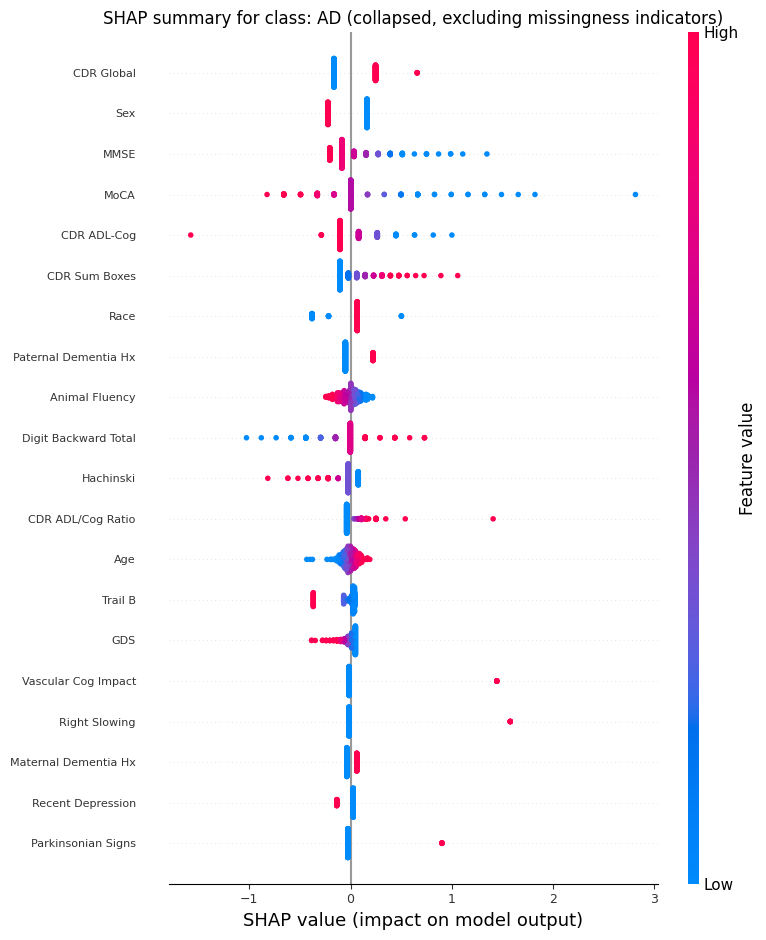

Saved: ..\output\shap_outputs\figures\summary_AD_clean.png


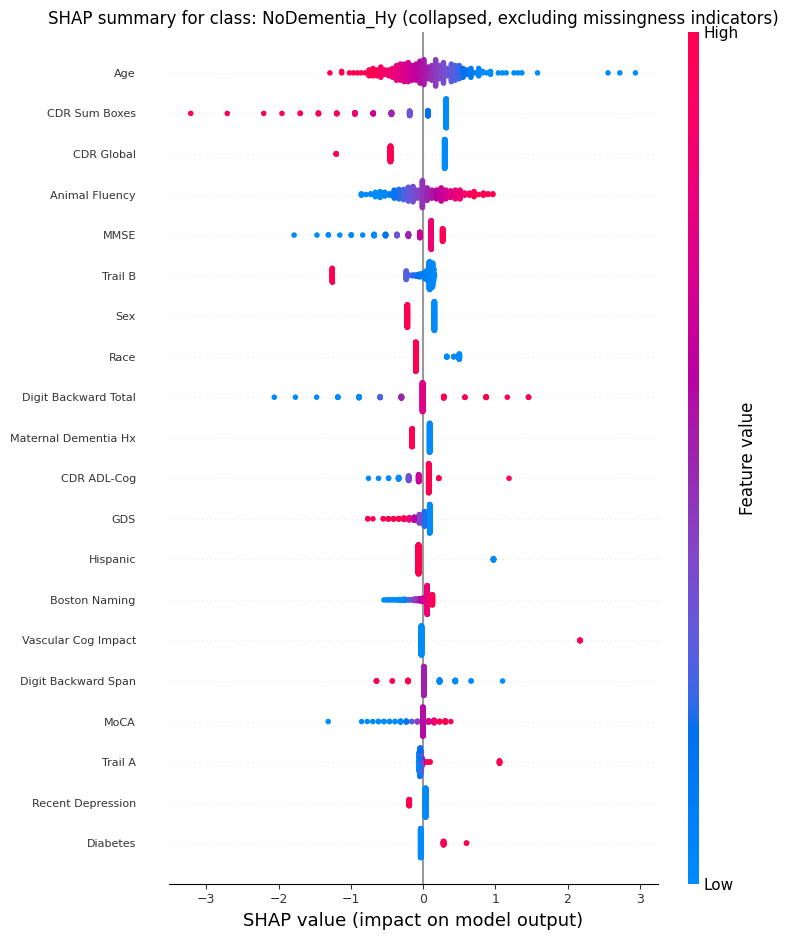

Saved: ..\output\shap_outputs\figures\summary_NoDementia_Hy_clean.png


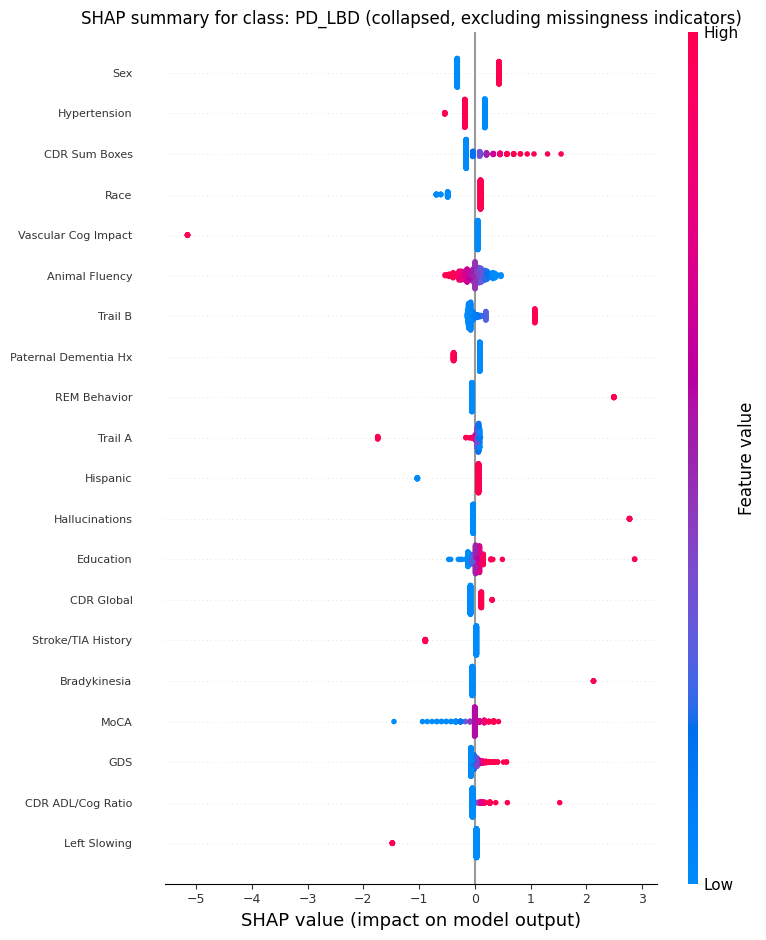

Saved: ..\output\shap_outputs\figures\summary_PD_LBD_clean.png


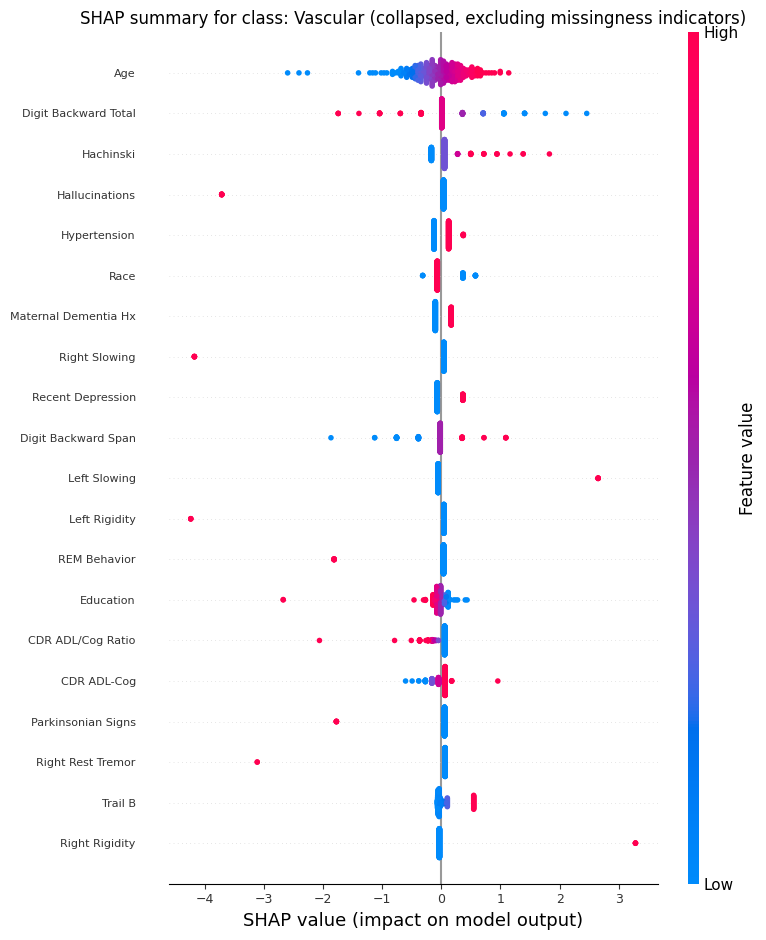

Saved: ..\output\shap_outputs\figures\summary_Vascular_clean.png


In [135]:
# Collapsed beeswarm plots: aggregate transformed columns back to base features
# and exclude transformed missingness indicators

feature_to_cols = build_feature_to_cols(feature_names_pre)

# base feature list from the explain matrix
collapsed_feature_bases = [
    collapse_feature_name(f)
    for f in feature_names_pre
    if not is_missing_feature_name(collapse_feature_name(f))
]

collapsed_feature_bases = list(dict.fromkeys(collapsed_feature_bases))  # preserve order

for k, cls in enumerate(class_order):

    collapsed_vals = []
    collapsed_names = []
    collapsed_data = []

    for base in collapsed_feature_bases:

        idxs = feature_to_cols.get(base, [])
        if len(idxs) == 0:
            continue

        # Sum SHAP values across transformed columns belonging to same base feature
        vals = shap_exp.values[:, idxs, k].sum(axis=1)
        collapsed_vals.append(vals)

        collapsed_names.append(plot_feature_name(base))

        # Use transformed matrix columns for coloring
        # (take the first column belonging to that base feature)
        col = X_explain[:, idxs[0]]

        if hasattr(col, "toarray"):
            col = col.toarray().ravel()
        else:
            col = np.asarray(col).ravel()

        collapsed_data.append(pd.to_numeric(col, errors="coerce"))

    collapsed_vals = np.array(collapsed_vals).T
    collapsed_data = np.array(collapsed_data).T

    plt.figure(figsize=(10, 8))

    shap.summary_plot(
        collapsed_vals,
        collapsed_data,
        feature_names=collapsed_names,
        show=False
    )

    ax = plt.gca()
    ax.tick_params(axis='y', labelsize=8)
    ax.tick_params(axis='x', labelsize=9)

    plt.gcf().subplots_adjust(left=0.40)

    plt.title(
        f"SHAP summary for class: {cls} (collapsed, excluding missingness indicators)",
        fontsize=12
    )

    save_current_fig(f"summary_{cls}_clean.png")

    plt.show()
    plt.close()

## 6) Global feature-importance tables

In [136]:

global_rows = []

for k, cls in enumerate(class_order):
    mean_abs_shap = np.abs(shap_exp.values[:, :, k]).mean(axis=0)
    tmp = pd.DataFrame({
        "feature": feature_names_pre,
        "mean_abs_shap": mean_abs_shap,
        "class": cls
    }).sort_values("mean_abs_shap", ascending=False)
    global_rows.append(tmp)

global_shap_df = pd.concat(global_rows, ignore_index=True)
global_csv = TABLE_DIR / "global_shap_importance_by_class.csv"
global_shap_df.to_csv(global_csv, index=False)

print("Saved:", global_csv)
display(global_shap_df.groupby("class", group_keys=False).head(15))


Saved: ..\output\shap_outputs\tables\global_shap_importance_by_class.csv


,feature,mean_abs_shap,class
0,num__NACCMMSE_missing,0.244019,AD
1,num__CDRGLOB,0.199364,AD
2,num__NACCMMSE,0.162885,AD
3,num__NACCMOCA,0.148374,AD
4,num__CDR_ADL_MINUS_COG,0.147745,AD
5,num__CDRSUM,0.126865,AD
6,cat__SEX_2,0.098957,AD
7,cat__SEX_1,0.090091,AD
8,num__NACCDAD,0.088505,AD
9,num__ANIMALS,0.075760,AD


In [137]:

# Displaying filters for cleaner SHAP presentation
# Keeping these variables in the model, but hiding them for display plots/tables

def is_display_feature_basic(feat: str) -> bool:
    return not is_missing_feature_name(feat)

collapsed_rows = []

for k, cls in enumerate(class_order):
    mean_abs_shap = np.abs(shap_exp.values[:, :, k]).mean(axis=0)
    tmp = pd.DataFrame({
        "feature_raw": feature_names_pre,
        "feature_base": [collapse_feature_name(f) for f in feature_names_pre],
        "mean_abs_shap": mean_abs_shap,
        "class": cls
    })
    tmp = (
        tmp.groupby(["class", "feature_base"], as_index=False)["mean_abs_shap"]
        .sum()
        .sort_values(["class", "mean_abs_shap"], ascending=[True, False])
    )
    collapsed_rows.append(tmp)

collapsed_global_shap_df = pd.concat(collapsed_rows, ignore_index=True)
collapsed_csv = TABLE_DIR / "global_shap_importance_collapsed.csv"
collapsed_global_shap_df.to_csv(collapsed_csv, index=False)

collapsed_global_shap_display_df = collapsed_global_shap_df[
    collapsed_global_shap_df["feature_base"].apply(is_display_feature_basic)
].copy()

collapsed_global_shap_display_df.to_csv(
    os.path.join(OUTPUT_DIR, "global_shap_importance_collapsed_display.csv"),
    index=False
)

print("Saved:", collapsed_csv)
display(collapsed_global_shap_display_df.groupby("class", group_keys=False).head(15))


Saved: ..\output\shap_outputs\tables\global_shap_importance_collapsed.csv


,class,feature_base,mean_abs_shap
1,AD,CDRGLOB,0.199364
2,AD,SEX,0.189049
3,AD,NACCMMSE,0.162885
4,AD,NACCMOCA,0.148374
5,AD,CDR_ADL_MINUS_COG,0.147745
6,AD,RACE,0.136818
7,AD,CDRSUM,0.126865
8,AD,NACCDAD,0.088505
9,AD,ANIMALS,0.075760
10,AD,DIGBACCT,0.075183


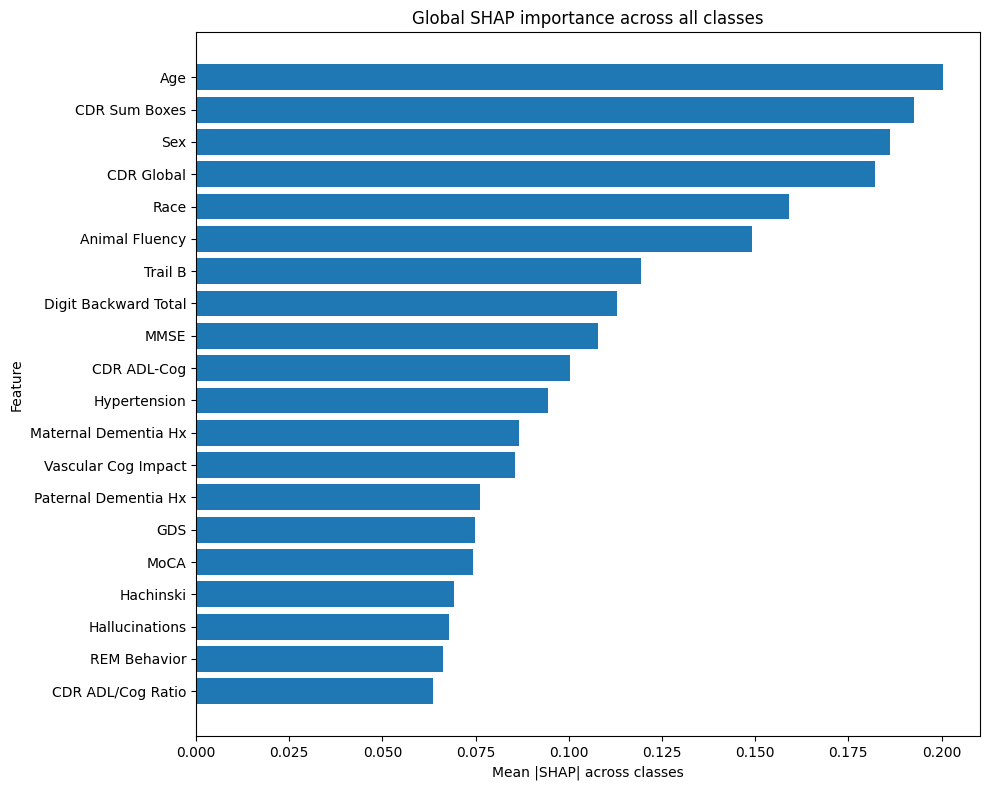

Saved: ..\output\shap_outputs\figures\bar_global_shap_overall.png


,feature_base,mean_abs_shap,feature_label
41,NACCAGE,0.200305,Age
9,CDRSUM,0.192701,CDR Sum Boxes
55,SEX,0.186265,Sex
8,CDRGLOB,0.182196,CDR Global
50,RACE,0.159031,Race
0,ANIMALS,0.149237,Animal Fluency
64,TRAILB,0.119294,Trail B
26,DIGBACCT,0.112820,Digit Backward Total
44,NACCMMSE,0.107914,MMSE
11,CDR_ADL_MINUS_COG,0.100411,CDR ADL-Cog


In [138]:
# Global SHAP importance across all classes (collapsed to base features)

global_overall_df = (
    collapsed_global_shap_display_df.groupby("feature_base", as_index=False)["mean_abs_shap"]
    .mean()
    .sort_values("mean_abs_shap", ascending=False)
)

global_overall_df["feature_label"] = global_overall_df["feature_base"].apply(plot_feature_name)

global_overall_df.to_csv(
    os.path.join(OUTPUT_DIR, "global_shap_importance_overall_collapsed.csv"),
    index=False
)

tmp = global_overall_df.head(20).iloc[::-1]

plt.figure(figsize=(10, 8))
plt.barh(tmp["feature_label"], tmp["mean_abs_shap"])
plt.xlabel("Mean |SHAP| across classes")
plt.ylabel("Feature")
plt.title("Global SHAP importance across all classes")
plt.tight_layout()
save_current_fig("bar_global_shap_overall.png")
plt.show()
plt.close()

display(global_overall_df.head(20))

In [139]:
# Signed SHAP direction tables at transformed-feature level

signed_rows = []

for k, cls in enumerate(class_order):
    mean_shap = shap_exp.values[:, :, k].mean(axis=0)
    mean_abs_shap = np.abs(shap_exp.values[:, :, k]).mean(axis=0)

    tmp = pd.DataFrame({
        "class": cls,
        "feature_raw": feature_names_pre,
        "mean_shap": mean_shap,
        "mean_abs_shap": mean_abs_shap,
    }).sort_values("mean_abs_shap", ascending=False)

    signed_rows.append(tmp)

signed_shap_df = pd.concat(signed_rows, ignore_index=True)
signed_shap_df.to_csv(
    os.path.join(OUTPUT_DIR, "global_shap_signed_transformed.csv"),
    index=False
)

display(signed_shap_df.groupby("class").head(15))

,class,feature_raw,mean_shap,mean_abs_shap
0,AD,num__NACCMMSE_missing,1.510955e-02,0.244019
1,AD,num__CDRGLOB,-1.095405e-02,0.199364
2,AD,num__NACCMMSE,-1.591604e-02,0.162885
3,AD,num__NACCMOCA,2.757064e-02,0.148374
4,AD,num__CDR_ADL_MINUS_COG,-9.826730e-03,0.147745
5,AD,num__CDRSUM,-1.052871e-02,0.126865
6,AD,cat__SEX_2,-4.035778e-03,0.098957
7,AD,cat__SEX_1,-3.674198e-03,0.090091
8,AD,num__NACCDAD,7.276907e-03,0.088505
9,AD,num__ANIMALS,-6.214204e-03,0.075760


In [140]:
# Signed SHAP direction tables at collapsed/base-feature level

collapsed_signed_rows = []

tmp_signed = signed_shap_df.copy()
tmp_signed["feature_base"] = tmp_signed["feature_raw"].apply(collapse_feature_name)

collapsed_signed_df = (
    tmp_signed.groupby(["class", "feature_base"], as_index=False)
    .agg(
        mean_shap=("mean_shap", "sum"),
        mean_abs_shap=("mean_abs_shap", "sum")
    )
    .sort_values(["class", "mean_abs_shap"], ascending=[True, False])
)

collapsed_signed_df.to_csv(
    os.path.join(OUTPUT_DIR, "global_shap_signed_collapsed.csv"),
    index=False
)

display(collapsed_signed_df.groupby("class").head(20))

,class,feature_base,mean_shap,mean_abs_shap
46,AD,NACCMMSE_missing,0.015110,0.244019
8,AD,CDRGLOB,-0.010954,0.199364
58,AD,SEX,-0.007710,0.189049
45,AD,NACCMMSE,-0.015916,0.162885
47,AD,NACCMOCA,0.027571,0.148374
...,...,...,...,...
227,Vascular,CDR_ADL_COG_RATIO,0.005762,0.089553
228,Vascular,CDR_ADL_MINUS_COG,0.005944,0.089374
267,Vascular,PARKSIGN,0.018302,0.089314
271,Vascular,RESTTRR,0.042371,0.083894


## 6b) Stability, normalized importance, and grouped categorical summaries

In [141]:

# Stability summary for collapsed/base features
stability_rows = []

for k, cls in enumerate(class_order):
    for base, idxs in build_feature_to_cols(feature_names_pre).items():
        vals = np.abs(shap_exp.values[:, idxs, k].sum(axis=1))
        stability_rows.append({
            "class": cls,
            "feature_base": base,
            "median_abs_shap": float(np.median(vals)),
            "mean_abs_shap": float(np.mean(vals)),
            "iqr_abs_shap": float(np.quantile(vals, 0.75) - np.quantile(vals, 0.25)),
        })

collapsed_stability_df = pd.DataFrame(stability_rows).sort_values(
    ["class", "mean_abs_shap"], ascending=[True, False]
)
collapsed_stability_df.to_csv(TABLE_DIR / "collapsed_feature_stability_summary.csv", index=False)

display(collapsed_stability_df.groupby("class", group_keys=False).head(15))


,class,feature_base,median_abs_shap,mean_abs_shap,iqr_abs_shap
10,AD,NACCMMSE_missing,0.169982,0.244019,0.226643
9,AD,CDRGLOB,0.164311,0.199364,0.082155
69,AD,SEX,0.161909,0.189049,0.061680
2,AD,NACCMMSE,0.085947,0.162885,0.119370
3,AD,NACCMOCA,0.001654,0.148374,0.162115
62,AD,CDR_ADL_MINUS_COG,0.105023,0.147745,0.000000
8,AD,CDRSUM,0.105564,0.126865,0.000000
70,AD,RACE,0.065469,0.121146,0.000000
67,AD,NACCDAD,0.051848,0.088505,0.000000
6,AD,ANIMALS,0.063847,0.075760,0.082489


In [142]:

# Normalized class-specific importance table (helps compare feature specificity across classes)
norm_df = collapsed_global_shap_display_df.copy()
norm_df["class_total"] = norm_df.groupby("class")["mean_abs_shap"].transform("sum")
norm_df["pct_within_class"] = 100 * norm_df["mean_abs_shap"] / norm_df["class_total"]

norm_df.to_csv(TABLE_DIR / "collapsed_feature_importance_normalized.csv", index=False)

subtypes_to_compare = ["AD", "PD_LBD", "Vascular"]
norm_compare = norm_df[norm_df["class"].isin(subtypes_to_compare)].copy()

top_compare_features = (
    norm_compare.groupby("feature_base", as_index=False)["mean_abs_shap"]
    .mean()
    .sort_values("mean_abs_shap", ascending=False)
    .head(15)["feature_base"]
    .tolist()
)

norm_pivot = (
    norm_compare[norm_compare["feature_base"].isin(top_compare_features)]
    .pivot(index="feature_base", columns="class", values="pct_within_class")
    .fillna(0)
)

norm_pivot.index = [plot_feature_name(x) for x in norm_pivot.index]
display(norm_pivot.sort_index())


class,AD,PD_LBD,Vascular
Age,2.133199,0.333342,9.468340
Animal Fluency,2.827552,4.483981,1.610557
CDR ADL-Cog,5.514172,1.448619,2.463852
CDR Global,7.440701,2.575353,1.948174
CDR Sum Boxes,4.734903,5.068396,2.007834
Digit Backward Total,2.806001,1.253208,4.954592
Hachinski,2.312580,1.075059,3.816922
Hallucinations,0.224485,2.764935,3.737920
Hypertension,1.356788,5.151909,3.593338
Paternal Dementia Hx,3.303220,4.152784,1.199338


## 7) Bar plots of top collapsed features per class

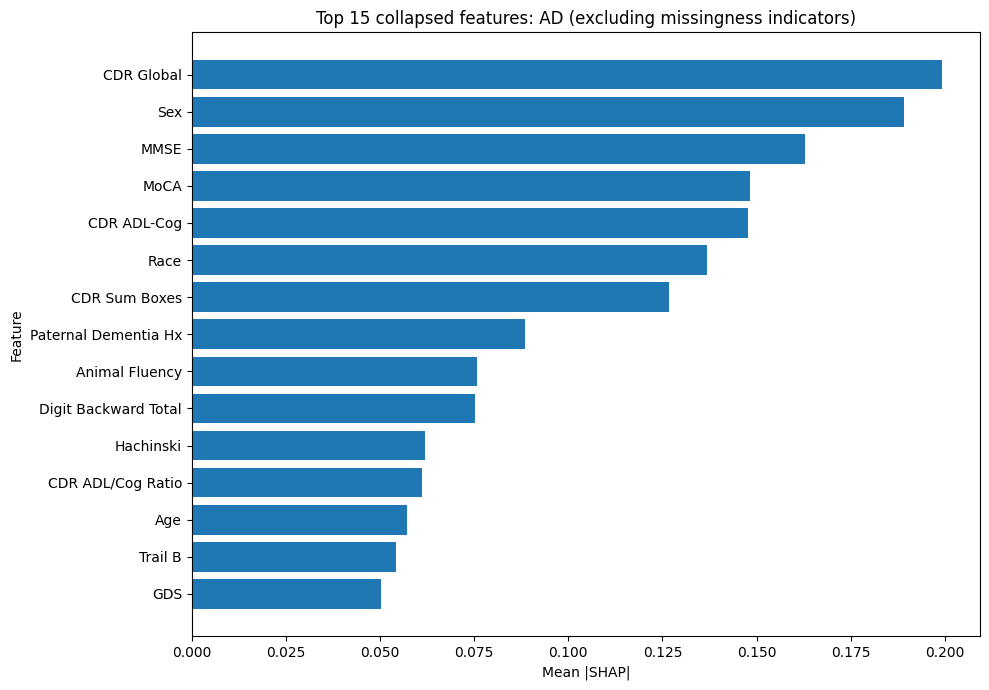

Saved: ..\output\shap_outputs\figures\bar_top_15_AD_display_clean.png


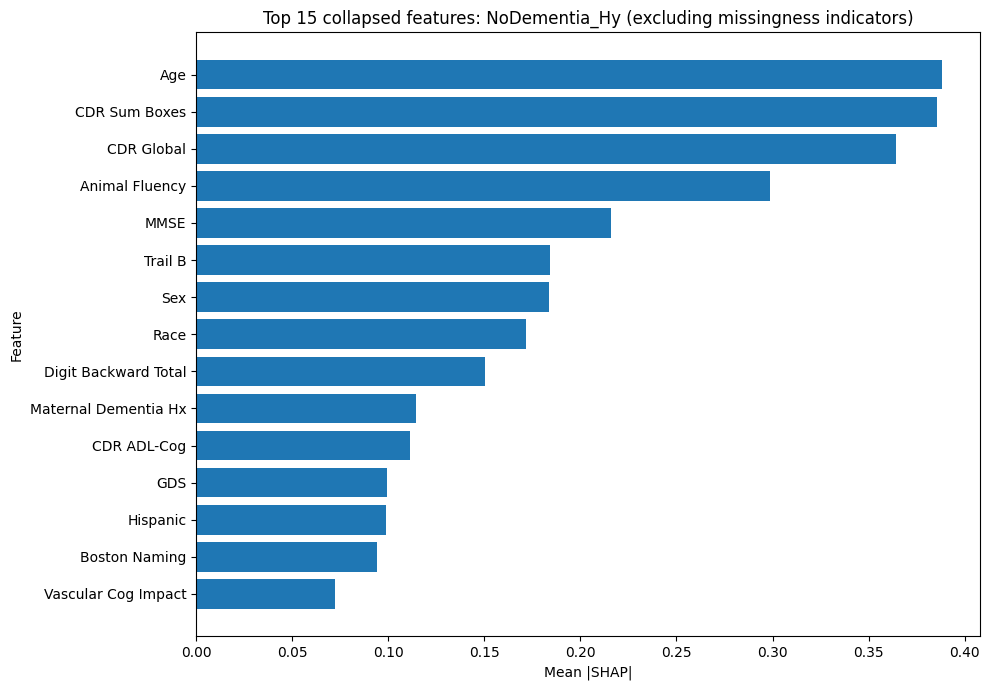

Saved: ..\output\shap_outputs\figures\bar_top_15_NoDementia_Hy_display_clean.png


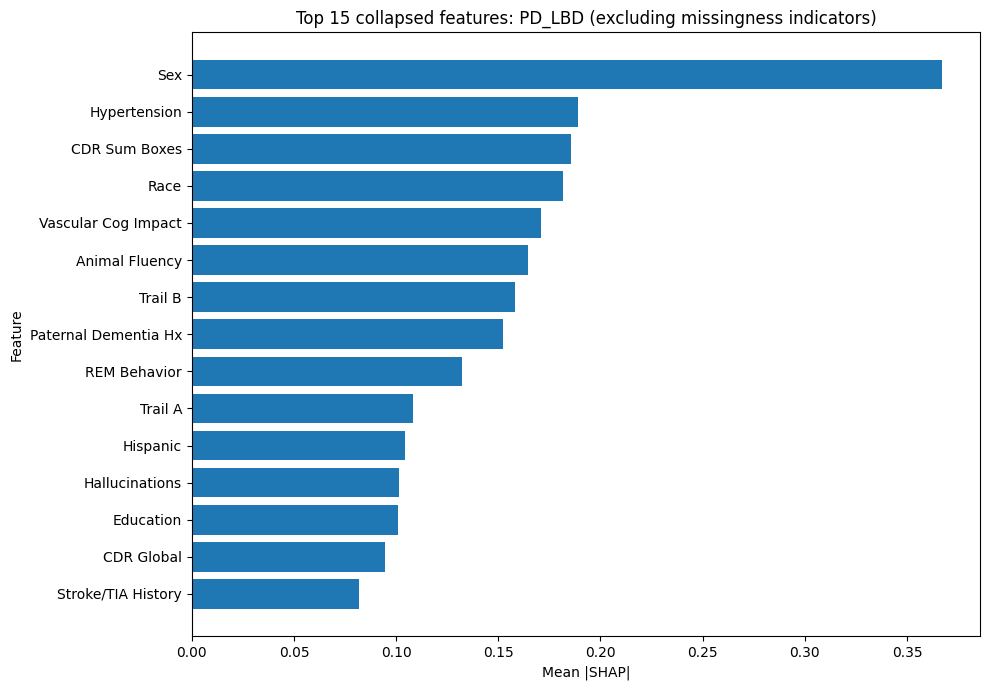

Saved: ..\output\shap_outputs\figures\bar_top_15_PD_LBD_display_clean.png


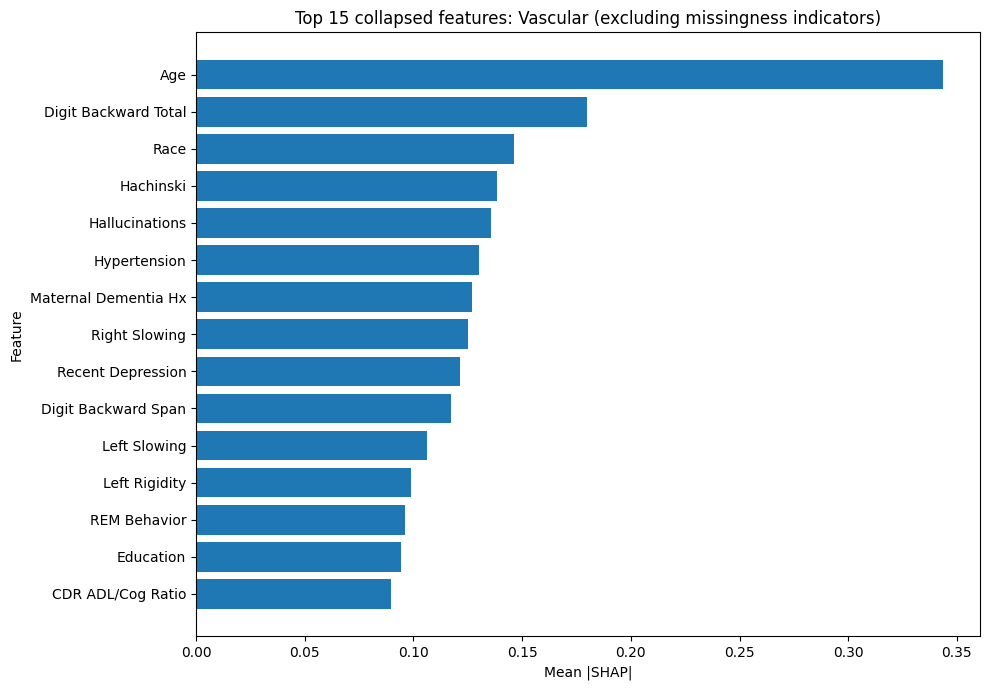

Saved: ..\output\shap_outputs\figures\bar_top_15_Vascular_display_clean.png


In [143]:
TOP_N = 15

for cls in class_order:
    tmp = (
        collapsed_global_shap_display_df.loc[
            collapsed_global_shap_display_df["class"] == cls
        ]
        .sort_values("mean_abs_shap", ascending=False)
        .head(TOP_N)
        .iloc[::-1]
        .copy()
    )

    tmp["feature_label"] = tmp["feature_base"].apply(plot_feature_name)

    plt.figure(figsize=(10, 7))
    plt.barh(tmp["feature_label"], tmp["mean_abs_shap"])
    plt.xlabel("Mean |SHAP|")
    plt.ylabel("Feature")
    plt.title(f"Top {TOP_N} collapsed features: {cls} (excluding missingness indicators)")
    plt.tight_layout()
    save_current_fig(f"bar_top_{TOP_N}_{cls}_display_clean.png")
    plt.show()
    plt.close()

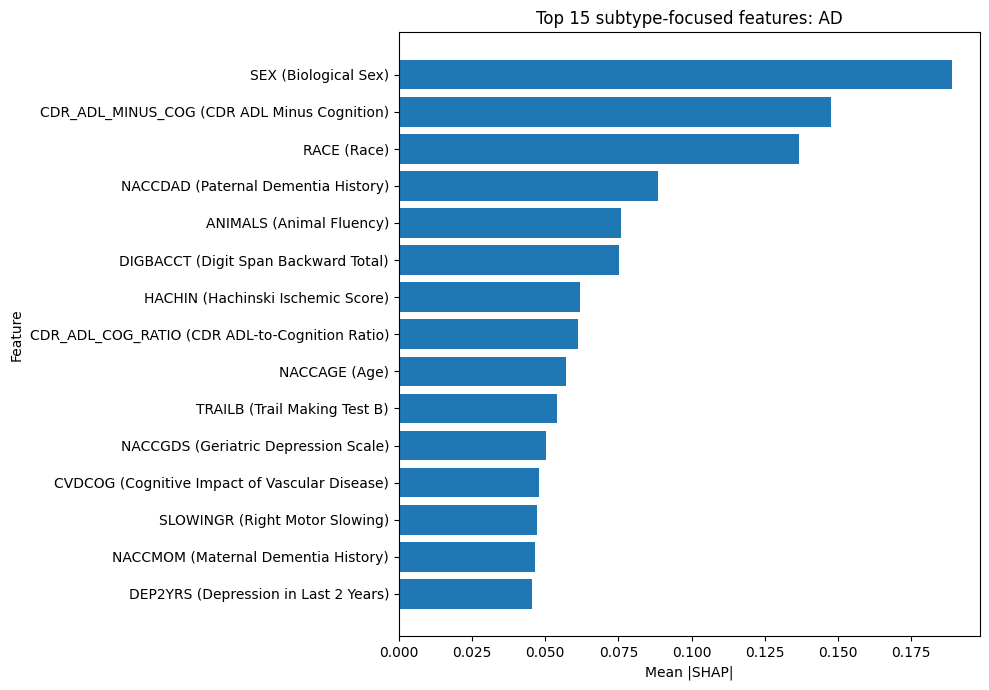

Saved: ..\output\shap_outputs\figures\bar_top_15_AD_clinical.png


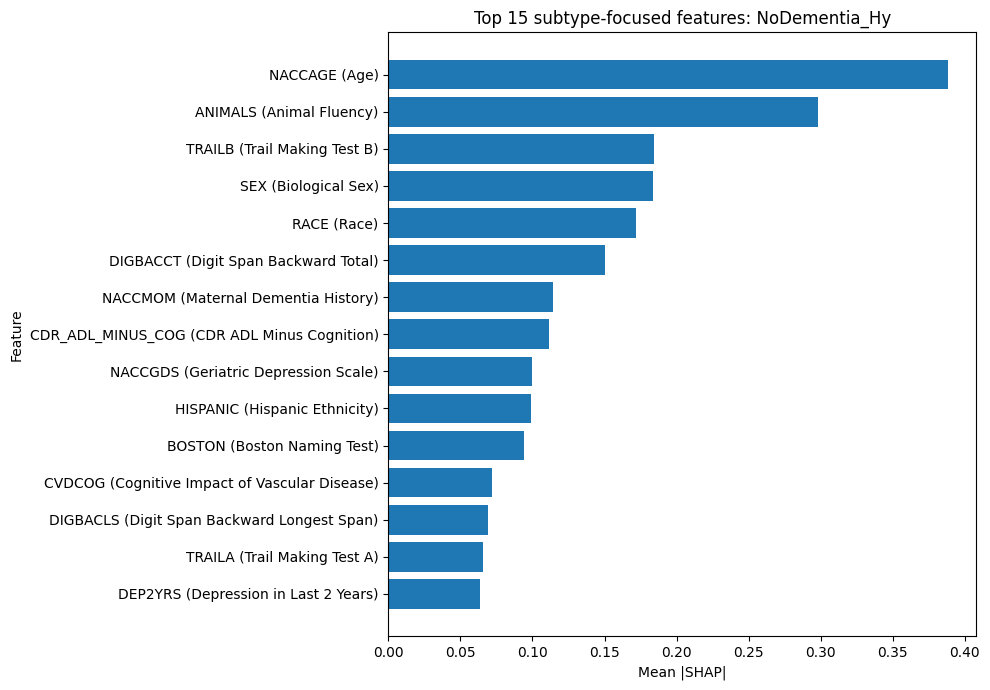

Saved: ..\output\shap_outputs\figures\bar_top_15_NoDementia_Hy_clinical.png


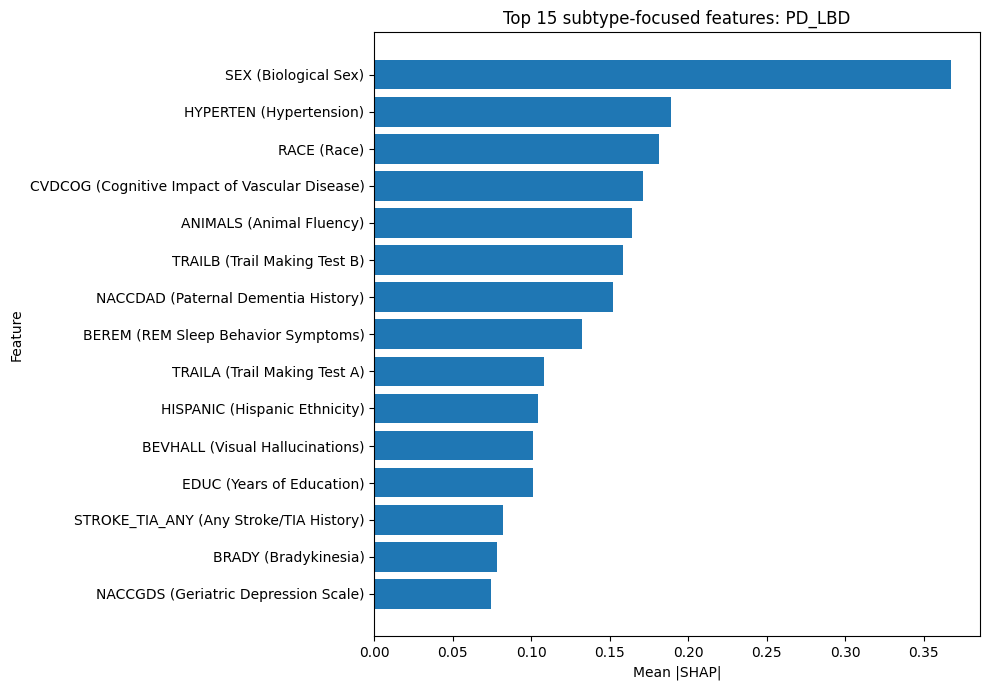

Saved: ..\output\shap_outputs\figures\bar_top_15_PD_LBD_clinical.png


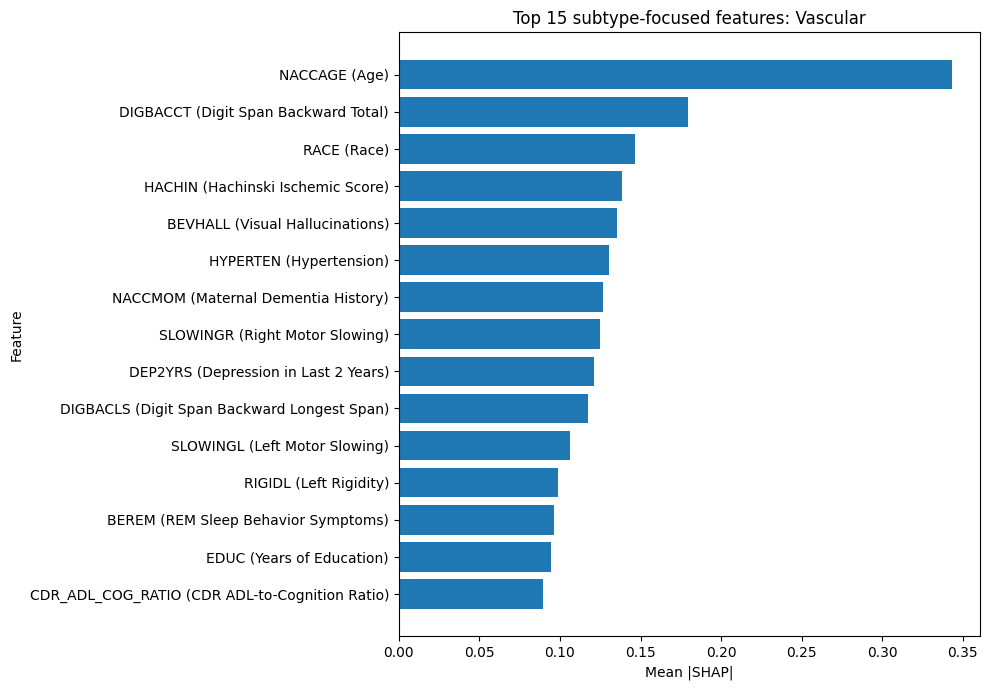

Saved: ..\output\shap_outputs\figures\bar_top_15_Vascular_clinical.png


In [144]:
# Clinical-subtype display set:
# hiding missingness + broad severity variables from the display only

HIDE_FOR_CLINICAL_PLOTS = {
    "CDRGLOB",
    "CDRSUM",
    "NACCMMSE",
    "NACCMOCA",
}

def is_display_feature_clinical(feat: str) -> bool:
    feat_u = str(feat).upper()
    if is_missing_feature_name(feat_u):
        return False
    if feat_u in HIDE_FOR_CLINICAL_PLOTS:
        return False
    return True

collapsed_global_shap_clinical_df = collapsed_global_shap_df[
    collapsed_global_shap_df["feature_base"].apply(is_display_feature_clinical)
].copy()

collapsed_global_shap_clinical_df.to_csv(
    os.path.join(OUTPUT_DIR, "global_shap_importance_collapsed_clinical.csv"),
    index=False
)

for cls in class_order:
    tmp = (
        collapsed_global_shap_clinical_df.loc[
            collapsed_global_shap_clinical_df["class"] == cls
        ]
        .sort_values("mean_abs_shap", ascending=False)
        .head(TOP_N)
        .iloc[::-1]
        .copy()
    )

    tmp["feature_label"] = tmp["feature_base"].apply(readable_feature_name)

    plt.figure(figsize=(10, 7))
    plt.barh(tmp["feature_label"], tmp["mean_abs_shap"])
    plt.xlabel("Mean |SHAP|")
    plt.ylabel("Feature")
    plt.title(f"Top {TOP_N} subtype-focused features: {cls}")
    plt.tight_layout()
    save_current_fig(f"bar_top_{TOP_N}_{cls}_clinical.png")
    plt.show()
    plt.close()

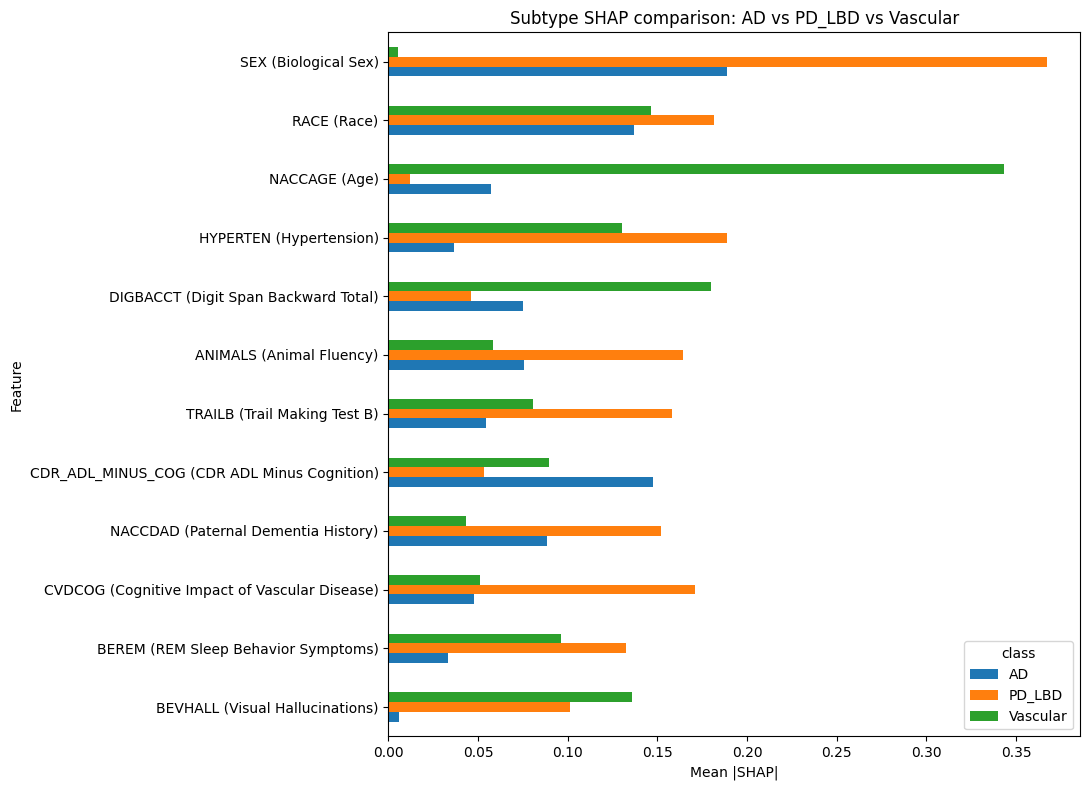

Saved: ..\output\shap_outputs\figures\bar_subtype_shap_comparison.png


In [145]:
# Subtype SHAP comparison plot: AD vs PD_LBD vs Vascular

subtypes_to_compare = ["AD", "PD_LBD", "Vascular"]

compare_df = collapsed_global_shap_clinical_df[
    collapsed_global_shap_clinical_df["class"].isin(subtypes_to_compare)
].copy()

top_features_compare = (
    compare_df.groupby("feature_base", as_index=False)["mean_abs_shap"]
    .mean()
    .sort_values("mean_abs_shap", ascending=False)
    .head(12)["feature_base"]
    .tolist()
)

plot_df = compare_df[compare_df["feature_base"].isin(top_features_compare)].copy()
plot_df["feature_label"] = plot_df["feature_base"].apply(readable_feature_name)

pivot_df = plot_df.pivot(index="feature_label", columns="class", values="mean_abs_shap").fillna(0)

# sorting by average importance
pivot_df["avg"] = pivot_df.mean(axis=1)
pivot_df = pivot_df.sort_values("avg", ascending=True).drop(columns="avg")

ax = pivot_df.plot(kind="barh", figsize=(11, 8))
ax.set_xlabel("Mean |SHAP|")
ax.set_ylabel("Feature")
ax.set_title("Subtype SHAP comparison: AD vs PD_LBD vs Vascular")
plt.tight_layout()
save_current_fig("bar_subtype_shap_comparison.png")
plt.show()
plt.close()

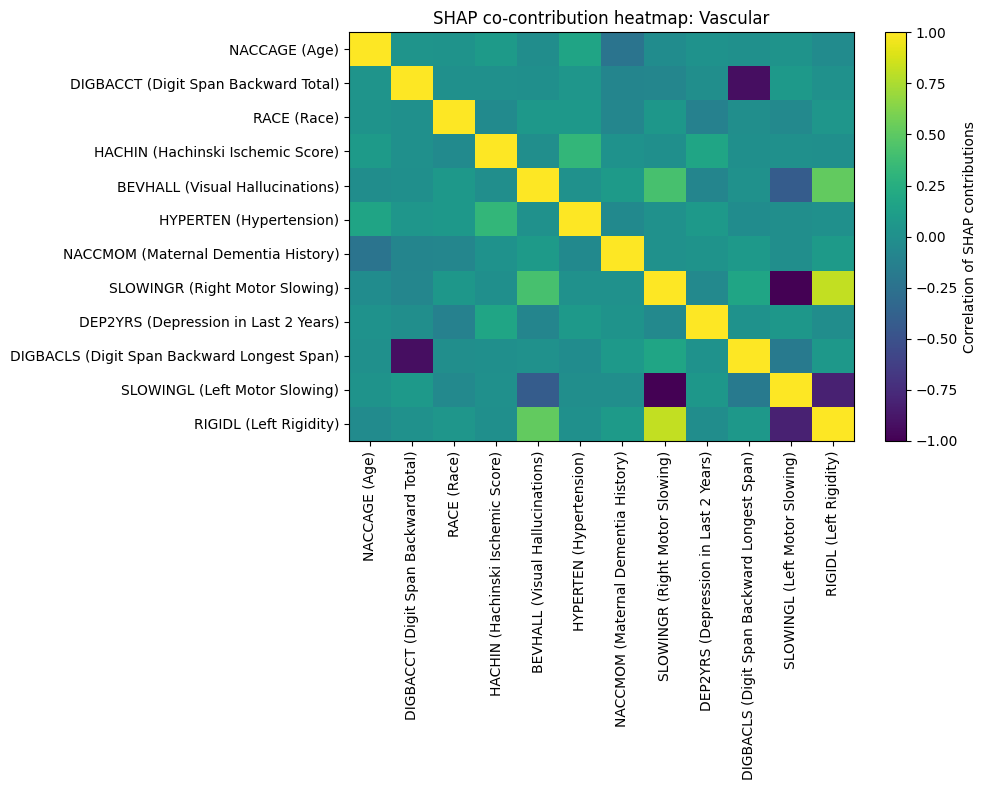

Saved: ..\output\shap_outputs\figures\heatmap_shap_cocontribution_Vascular.png


In [146]:
# SHAP co-contribution heatmap 

target_cls = "Vascular"   # change to "AD" or "PD_LBD" if desired
k = list(class_order).index(target_cls)

top_feats = (
    collapsed_global_shap_clinical_df.loc[
        collapsed_global_shap_clinical_df["class"] == target_cls
    ]
    .sort_values("mean_abs_shap", ascending=False)
    .head(12)["feature_base"]
    .tolist()
)

feature_to_cols = {}
for j, f in enumerate(feature_names_pre):
    base = collapse_feature_name(f)
    feature_to_cols.setdefault(base, []).append(j)

heatmap_matrix = []
labels = []

for feat in top_feats:
    idxs = feature_to_cols.get(feat, [])
    if len(idxs) == 0:
        continue
    vals = shap_exp.values[:, idxs, k].sum(axis=1)
    heatmap_matrix.append(vals)
    labels.append(readable_feature_name(feat))

heatmap_df = pd.DataFrame(heatmap_matrix, index=labels).T
corr_df = heatmap_df.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_df, aspect="auto")
plt.xticks(range(len(corr_df.columns)), corr_df.columns, rotation=90)
plt.yticks(range(len(corr_df.index)), corr_df.index)
plt.colorbar(label="Correlation of SHAP contributions")
plt.title(f"SHAP co-contribution heatmap: {target_cls}")
plt.tight_layout()
save_current_fig(f"heatmap_shap_cocontribution_{target_cls}.png")
plt.show()
plt.close()

## 7b) Dependence plots for top numeric base features

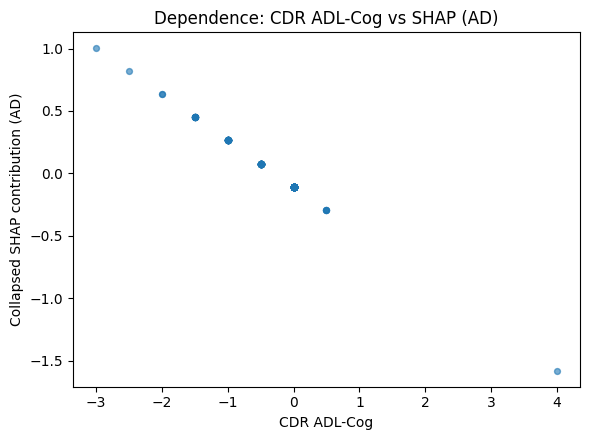

Saved: ..\output\shap_outputs\figures\dependence_AD_CDR_ADL_MINUS_COG.png


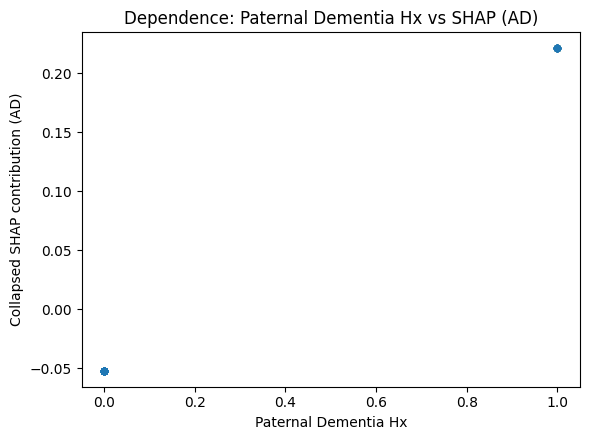

Saved: ..\output\shap_outputs\figures\dependence_AD_NACCDAD.png


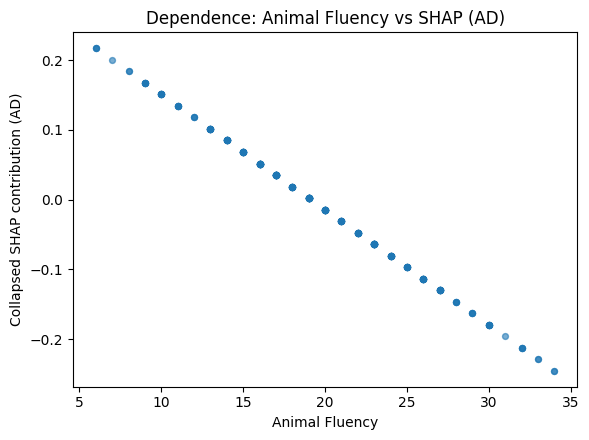

Saved: ..\output\shap_outputs\figures\dependence_AD_ANIMALS.png


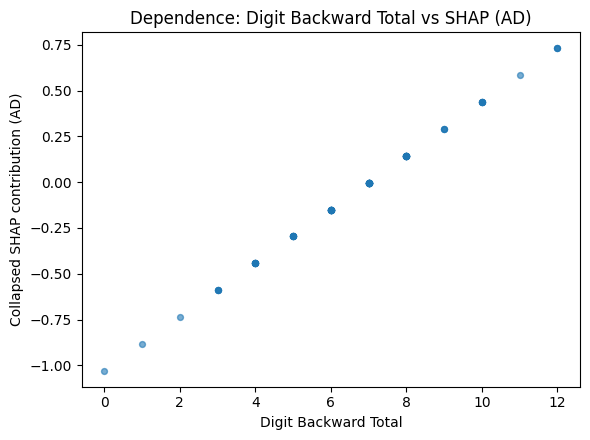

Saved: ..\output\shap_outputs\figures\dependence_AD_DIGBACCT.png


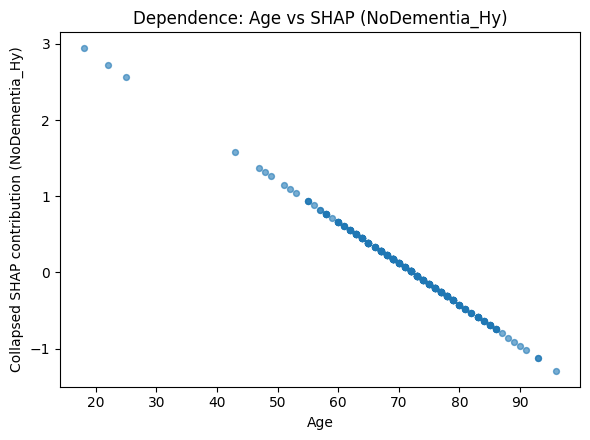

Saved: ..\output\shap_outputs\figures\dependence_NoDementia_Hy_NACCAGE.png


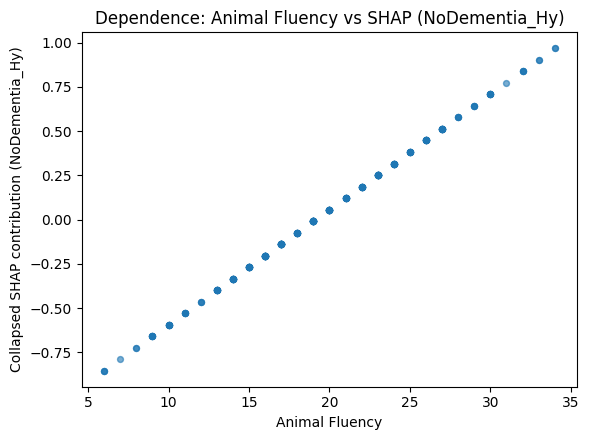

Saved: ..\output\shap_outputs\figures\dependence_NoDementia_Hy_ANIMALS.png


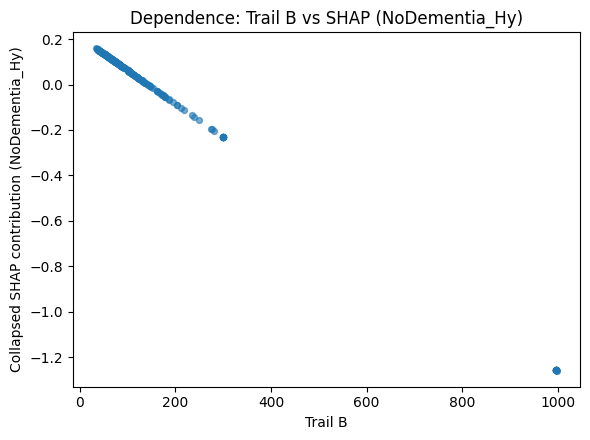

Saved: ..\output\shap_outputs\figures\dependence_NoDementia_Hy_TRAILB.png


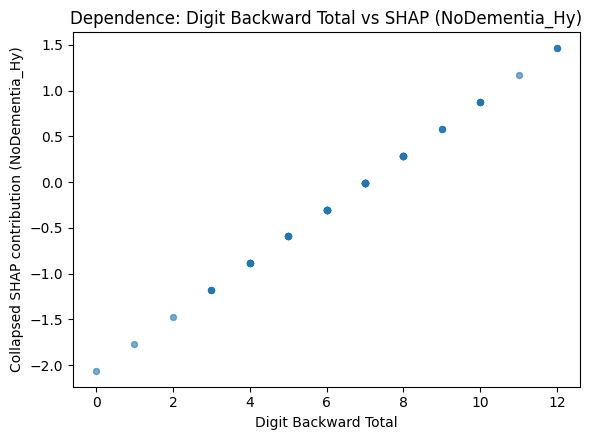

Saved: ..\output\shap_outputs\figures\dependence_NoDementia_Hy_DIGBACCT.png


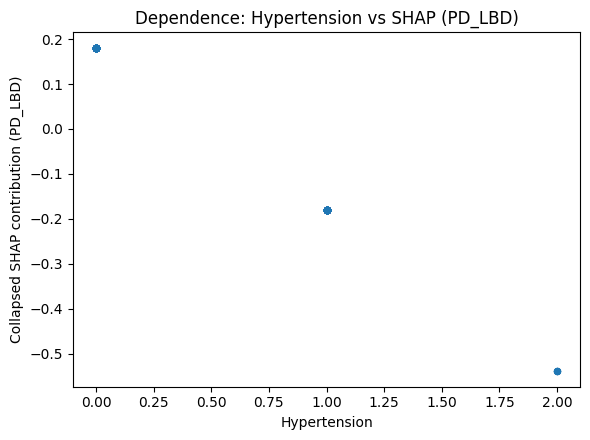

Saved: ..\output\shap_outputs\figures\dependence_PD_LBD_HYPERTEN.png


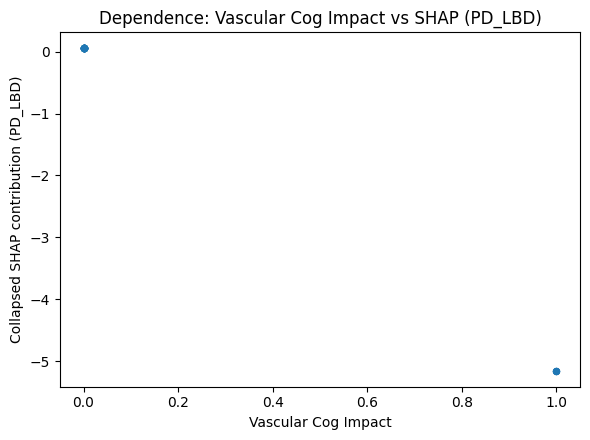

Saved: ..\output\shap_outputs\figures\dependence_PD_LBD_CVDCOG.png


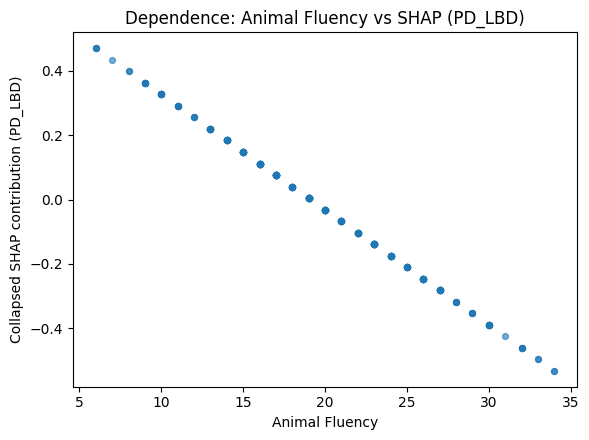

Saved: ..\output\shap_outputs\figures\dependence_PD_LBD_ANIMALS.png


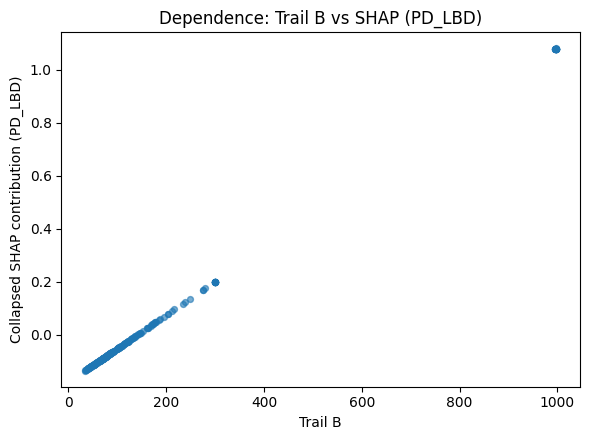

Saved: ..\output\shap_outputs\figures\dependence_PD_LBD_TRAILB.png


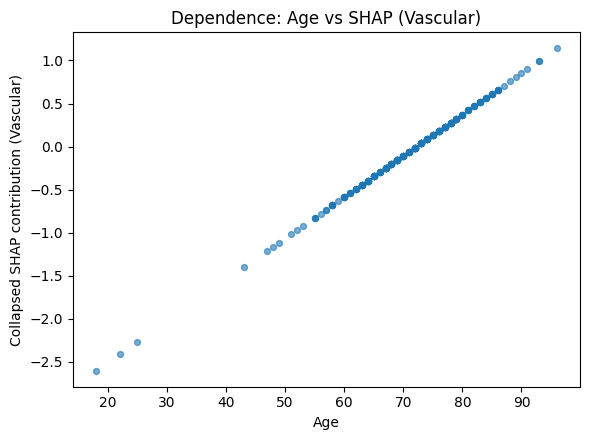

Saved: ..\output\shap_outputs\figures\dependence_Vascular_NACCAGE.png


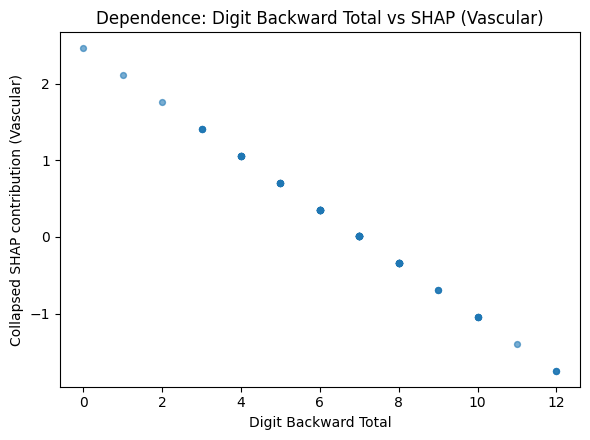

Saved: ..\output\shap_outputs\figures\dependence_Vascular_DIGBACCT.png


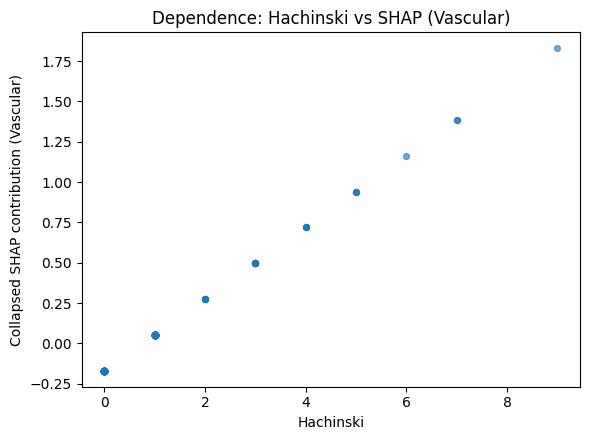

Saved: ..\output\shap_outputs\figures\dependence_Vascular_HACHIN.png


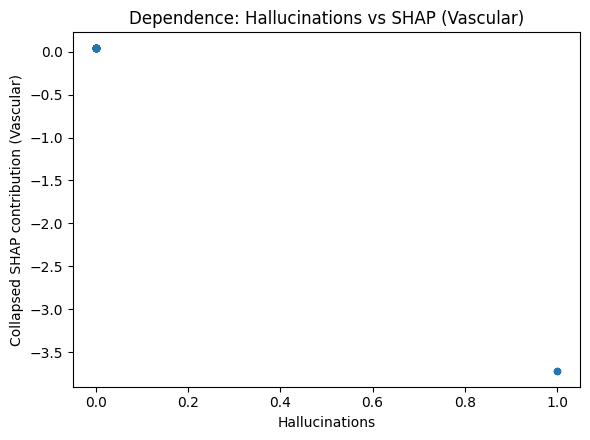

Saved: ..\output\shap_outputs\figures\dependence_Vascular_BEVHALL.png


In [147]:

# Custom dependence plots at the collapsed/base-feature level.
# This avoids duplicated one-hot displays and uses the original raw feature value on the x-axis.

candidate_numeric_bases = [
    c for c in X_test.columns
    if pd.api.types.is_numeric_dtype(X_test[c]) or pd.api.types.is_bool_dtype(X_test[c])
]

feature_to_cols = build_feature_to_cols(feature_names_pre)

for cls in class_order:
    cls_idx = list(class_order).index(cls)
    top_bases = (
        collapsed_global_shap_clinical_df.loc[
            (collapsed_global_shap_clinical_df["class"] == cls) &
            (collapsed_global_shap_clinical_df["feature_base"].isin(candidate_numeric_bases))
        ]
        .sort_values("mean_abs_shap", ascending=False)
        .head(MAX_DEPENDENCE_PLOTS_PER_CLASS)["feature_base"]
        .tolist()
    )

    for base in top_bases:
        idxs = feature_to_cols.get(base, [])
        if not idxs:
            continue

        x_vals = pd.to_numeric(X_test_explain[base], errors="coerce").values if "X_test_explain" in globals() else pd.to_numeric(X_test.iloc[:sample_size][base], errors="coerce").values
        y_vals = shap_exp.values[:, idxs, cls_idx].sum(axis=1)

        plot_df = pd.DataFrame({"x": x_vals, "shap": y_vals}).dropna()
        if plot_df.empty:
            continue

        plt.figure(figsize=(6, 4.5))
        plt.scatter(plot_df["x"], plot_df["shap"], alpha=0.6, s=18)
        plt.xlabel(plot_feature_name(base))
        plt.ylabel(f"Collapsed SHAP contribution ({cls})")
        plt.title(f"Dependence: {plot_feature_name(base)} vs SHAP ({cls})")
        save_current_fig(f"dependence_{cls}_{base}.png")
        plt.close()


## 8) Calibration checks

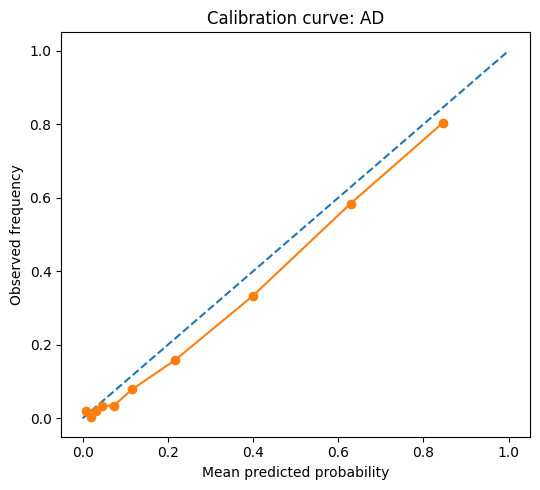

Saved: ..\output\shap_outputs\figures\calibration_curve_AD.png


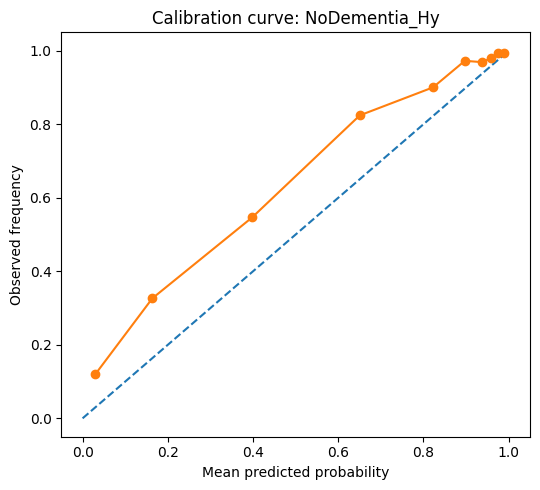

Saved: ..\output\shap_outputs\figures\calibration_curve_NoDementia_Hy.png


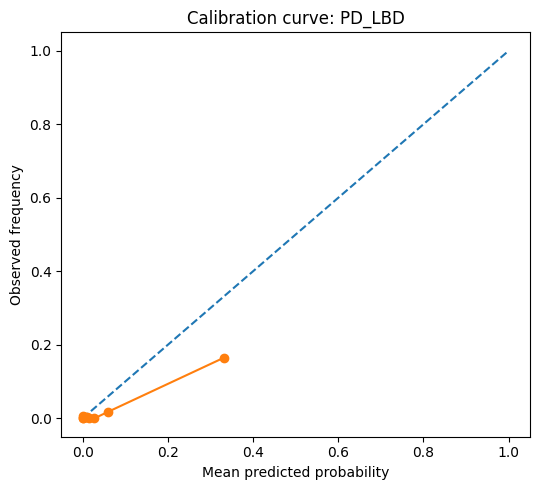

Saved: ..\output\shap_outputs\figures\calibration_curve_PD_LBD.png


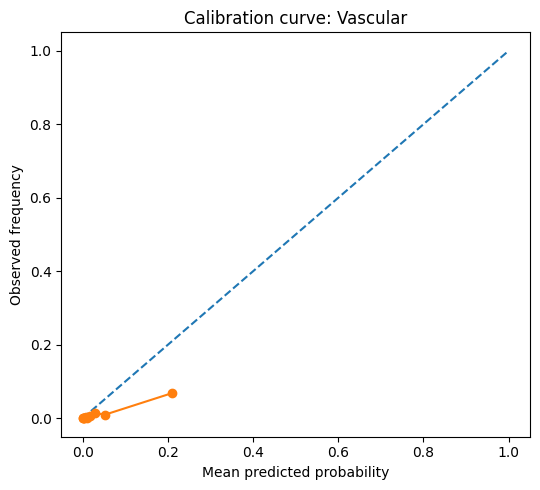

Saved: ..\output\shap_outputs\figures\calibration_curve_Vascular.png


,class,brier_score,mean_predicted_probability,event_rate
3,Vascular,0.012146,0.033872,0.010316
2,PD_LBD,0.016320,0.045537,0.019945
0,AD,0.093197,0.238554,0.207359
1,NoDementia_Hy,0.098928,0.682037,0.762380


In [148]:

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

proba_test = clf_best.predict_proba(X_test)

calibration_rows = []

for j, cls in enumerate(class_order):
    y_bin = (y_test.values == cls).astype(int)
    frac_pos, mean_pred = calibration_curve(y_bin, proba_test[:, j], n_bins=10, strategy="quantile")

    plt.figure(figsize=(5.5, 5))
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.plot(mean_pred, frac_pos, marker="o")
    plt.xlabel("Mean predicted probability")
    plt.ylabel("Observed frequency")
    plt.title(f"Calibration curve: {cls}")
    save_current_fig(f"calibration_curve_{cls}.png")
    plt.close()

    calibration_rows.append({
        "class": cls,
        "brier_score": float(brier_score_loss(y_bin, proba_test[:, j])),
        "mean_predicted_probability": float(np.mean(proba_test[:, j])),
        "event_rate": float(np.mean(y_bin)),
    })

calibration_df = pd.DataFrame(calibration_rows).sort_values("brier_score")
calibration_df.to_csv(TABLE_DIR / "calibration_summary.csv", index=False)
display(calibration_df)


## 9) Threshold-aware prediction table for the vascular override

In [149]:

proba_test = clf_best.predict_proba(X_test)


base_pred_test = np.array([class_order[np.argmax(p)] for p in proba_test])
final_pred_test = predict_with_vascular_threshold(proba_test, class_order, best_T)

vas_idx = list(class_order).index("Vascular")

threshold_df = pd.DataFrame({
    "NACCID": df4.loc[X_test.index, "NACCID"].values,
    "true_label": y_test.values,
    "base_pred": base_pred_test,
    "final_pred": final_pred_test,
    "prob_vascular": proba_test[:, vas_idx],
    "vascular_threshold": best_T,
    "vascular_margin": proba_test[:, vas_idx] - best_T
})

for j, cls in enumerate(class_order):
    threshold_df[f"prob_{cls}"] = proba_test[:, j]
    
threshold_csv = TABLE_DIR / "vascular_threshold_analysis_test.csv"
threshold_df.to_csv(threshold_csv, index=False)

vas_idx = list(class_order).index("Vascular")

threshold_df["vascular_prob"] = proba_test[:, vas_idx]
threshold_df["vascular_margin"] = threshold_df["vascular_prob"] - best_T
threshold_df["vascular_override_applied"] = (
    (threshold_df["final_pred"] == "Vascular") &
    (threshold_df["base_pred"] != "Vascular")
)

threshold_df["near_vascular_threshold"] = threshold_df["vascular_margin"].abs() <= 0.05

vascular_threshold_csv = TABLE_DIR / "vascular_threshold_analysis_detailed.csv"
threshold_df.to_csv(vascular_threshold_csv, index=False)

display(
    threshold_df.sort_values("vascular_margin", ascending=False).head(20)
)

print("Saved:", threshold_csv)
display(threshold_df.head(10))


,NACCID,true_label,base_pred,final_pred,prob_vascular,vascular_threshold,vascular_margin,prob_AD,prob_NoDementia_Hy,prob_PD_LBD,prob_Vascular,vascular_prob,vascular_override_applied,near_vascular_threshold
203,NACC087117,Vascular,Vascular,Vascular,0.956321,0.39,0.566321,0.039613,0.004054,0.000013,0.956321,0.956321,False,False
1049,NACC344666,AD,Vascular,Vascular,0.945126,0.39,0.555126,0.048385,0.006333,0.000156,0.945126,0.945126,False,False
2091,NACC340799,AD,Vascular,Vascular,0.923182,0.39,0.533182,0.041611,0.035183,0.000024,0.923182,0.923182,False,False
1737,NACC846464,Vascular,Vascular,Vascular,0.908175,0.39,0.518175,0.067159,0.022311,0.002355,0.908175,0.908175,False,False
1254,NACC861111,NoDementia_Hy,Vascular,Vascular,0.885425,0.39,0.495425,0.044074,0.067742,0.002759,0.885425,0.885425,False,False
1484,NACC822377,Vascular,Vascular,Vascular,0.876047,0.39,0.486047,0.111037,0.012911,0.000004,0.876047,0.876047,False,False
547,NACC920443,NoDementia_Hy,Vascular,Vascular,0.851351,0.39,0.461351,0.106204,0.041912,0.000533,0.851351,0.851351,False,False
748,NACC389961,Vascular,Vascular,Vascular,0.842351,0.39,0.452351,0.148605,0.009014,0.000030,0.842351,0.842351,False,False
2267,NACC388114,Vascular,Vascular,Vascular,0.836633,0.39,0.446633,0.027858,0.135446,0.000063,0.836633,0.836633,False,False
2314,NACC777183,NoDementia_Hy,Vascular,Vascular,0.829690,0.39,0.439690,0.045038,0.119127,0.006144,0.829690,0.829690,False,False


Saved: ..\output\shap_outputs\tables\vascular_threshold_analysis_test.csv


,NACCID,true_label,base_pred,final_pred,prob_vascular,vascular_threshold,vascular_margin,prob_AD,prob_NoDementia_Hy,prob_PD_LBD,prob_Vascular,vascular_prob,vascular_override_applied,near_vascular_threshold
0,NACC056862,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.005251,0.39,-0.384749,0.081939,0.910434,0.002375,0.005251,0.005251,False,False
1,NACC774813,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.001838,0.39,-0.388162,0.079952,0.914570,0.003639,0.001838,0.001838,False,False
2,NACC989206,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.003199,0.39,-0.386801,0.062824,0.932811,0.001166,0.003199,0.003199,False,False
3,NACC735141,AD,AD,AD,0.040540,0.39,-0.349460,0.777575,0.084701,0.097183,0.040540,0.040540,False,False
4,NACC252819,NoDementia_Hy,AD,AD,0.035007,0.39,-0.354993,0.573230,0.379412,0.012352,0.035007,0.035007,False,False
5,NACC205986,NoDementia_Hy,AD,AD,0.023658,0.39,-0.366342,0.492703,0.434148,0.049491,0.023658,0.023658,False,False
6,NACC148349,Vascular,AD,AD,0.066996,0.39,-0.323004,0.670536,0.103018,0.159450,0.066996,0.066996,False,False
7,NACC029156,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.007337,0.39,-0.382663,0.058775,0.916709,0.017178,0.007337,0.007337,False,False
8,NACC522352,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.001406,0.39,-0.388594,0.017129,0.980902,0.000563,0.001406,0.001406,False,False
9,NACC532829,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.001352,0.39,-0.388648,0.034934,0.962790,0.000924,0.001352,0.001352,False,False


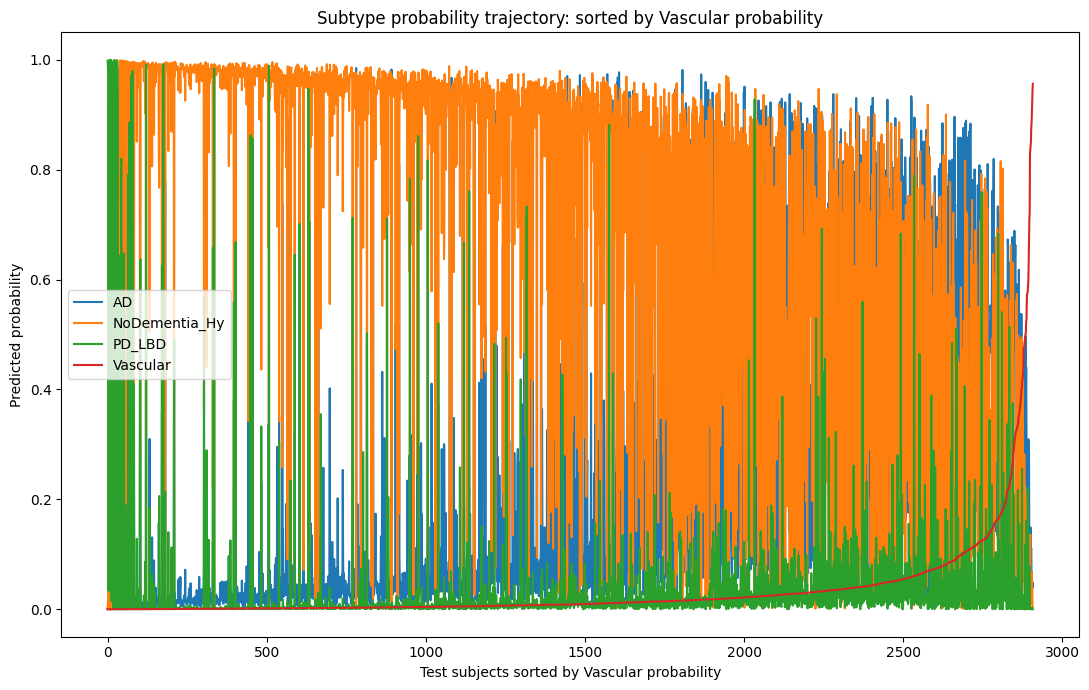

Saved: ..\output\shap_outputs\figures\trajectory_probabilities_sorted_by_Vascular.png


In [150]:
# Subtype probability trajectory visualization

target_cls = "Vascular"  
target_col = f"prob_{target_cls}"

traj_df = threshold_df.copy().sort_values(target_col).reset_index(drop=True)

plt.figure(figsize=(11, 7))
for cls in class_order:
    plt.plot(traj_df[f"prob_{cls}"].values, label=cls)

plt.xlabel(f"Test subjects sorted by {target_cls} probability")
plt.ylabel("Predicted probability")
plt.title(f"Subtype probability trajectory: sorted by {target_cls} probability")
plt.legend()
plt.tight_layout()
save_current_fig(f"trajectory_probabilities_sorted_by_{target_cls}.png")
plt.show()
plt.close()

## 10) Local explanations for selected participants

In [151]:

example_indices = []

# threshold_df is aligned row-for-row with X_test
# X_explain / shap_exp only contain the first sample_size rows
threshold_explain_df = threshold_df.iloc[:sample_size].copy()

threshold_explain_df = threshold_explain_df.reset_index(drop=True)

# 1) Highest-confidence predicted AD
ad_mask = threshold_explain_df["final_pred"] == "AD"
if ad_mask.any():
    if "prob_AD" in threshold_explain_df.columns:
        ad_pos = threshold_explain_df.loc[ad_mask, "prob_AD"].idxmax()
    else:
        ad_pos = threshold_explain_df.index[ad_mask][0]
    example_indices.append(int(ad_pos))

# 2) Highest-confidence predicted PD_LBD
pd_mask = threshold_explain_df["final_pred"] == "PD_LBD"
if pd_mask.any():
    if "prob_PD_LBD" in threshold_explain_df.columns:
        pd_pos = threshold_explain_df.loc[pd_mask, "prob_PD_LBD"].idxmax()
    else:
        pd_pos = threshold_explain_df.index[pd_mask][0]
    example_indices.append(int(pd_pos))

# 3) Highest vascular margin case
vas_mask = threshold_explain_df["final_pred"] == "Vascular"
if vas_mask.any():
    vas_pos = threshold_explain_df.loc[vas_mask, "vascular_margin"].idxmax()
    example_indices.append(int(vas_pos))

# 4) Closest case to vascular threshold
near_pos = threshold_explain_df["vascular_margin"].abs().idxmin()
example_indices.append(int(near_pos))

example_indices = list(dict.fromkeys(example_indices))
print("Selected example positions in X_explain:", example_indices)

Selected example positions in X_explain: [195, 79, 203, 32]


In [152]:
print("sample_size =", sample_size)
print("example_indices =", example_indices)
print("max example index =", max(example_indices) if len(example_indices) else None)

sample_size = 300
example_indices = [195, 79, 203, 32]
max example index = 203


In [153]:
# Aligning all objects to the explained subset

X_test_explain = X_test.iloc[:sample_size].copy()
y_test_explain = y_test.iloc[:sample_size].reset_index(drop=True).copy()
threshold_explain_df = threshold_df.iloc[:sample_size].reset_index(drop=True).copy()

print("X_test_explain shape:", X_test_explain.shape)
print("y_test_explain shape:", y_test_explain.shape)
print("threshold_explain_df shape:", threshold_explain_df.shape)
print("X_explain shape:", X_explain.shape)
print("SHAP values shape:", shap_exp.values.shape)
print("Example indices:", example_indices)

X_test_explain shape: (300, 72)
y_test_explain shape: (300,)
threshold_explain_df shape: (300, 14)
X_explain shape: (300, 79)
SHAP values shape: (300, 79, 4)
Example indices: [195, 79, 203, 32]


## 10b) Optional probability-space local SHAP (selected cases only)

In [154]:

# Optional local probability-space SHAP using KernelExplainer on predict_proba.
# This is slower, so we only run it for the selected local examples.

prob_local_shap = None
prob_local_example_map = {}

if USE_PROBABILITY_KERNEL_SHAP_FOR_LOCAL and len(example_indices) > 0:
    kernel_bg = X_background_dense[: min(KERNEL_BG_SIZE, X_background_dense.shape[0])]
    explain_dense = X_explain_dense[example_indices]

    def predict_proba_from_preprocessed(arr):
        arr = np.asarray(arr)
        return lr_model.predict_proba(arr)

    kernel_explainer = shap.KernelExplainer(
        predict_proba_from_preprocessed,
        kernel_bg,
        link="identity"
    )

    prob_local_shap = kernel_explainer.shap_values(
        explain_dense,
        nsamples=KERNEL_NSAMPLES
    )

    for pos, i in enumerate(example_indices):
        prob_local_example_map[i] = pos

    print("Computed local probability SHAP for indices:", example_indices)
else:
    print("Skipped local probability SHAP.")


100%|██████████| 4/4 [00:00<00:00, 66.47it/s]

Computed local probability SHAP for indices: [195, 79, 203, 32]


Explain subset row : 195
Original X_test idx: 37353
NACCID            : NACC973323
True label        : AD
Final prediction  : AD
Probabilities     : {np.str_('AD'): np.float64(0.9773), np.str_('NoDementia_Hy'): np.float64(0.0073), np.str_('PD_LBD'): np.float64(0.0037), np.str_('Vascular'): np.float64(0.0117)}
Vascular margin   : -0.3783

--- Collapsed waterfall for class: AD ---


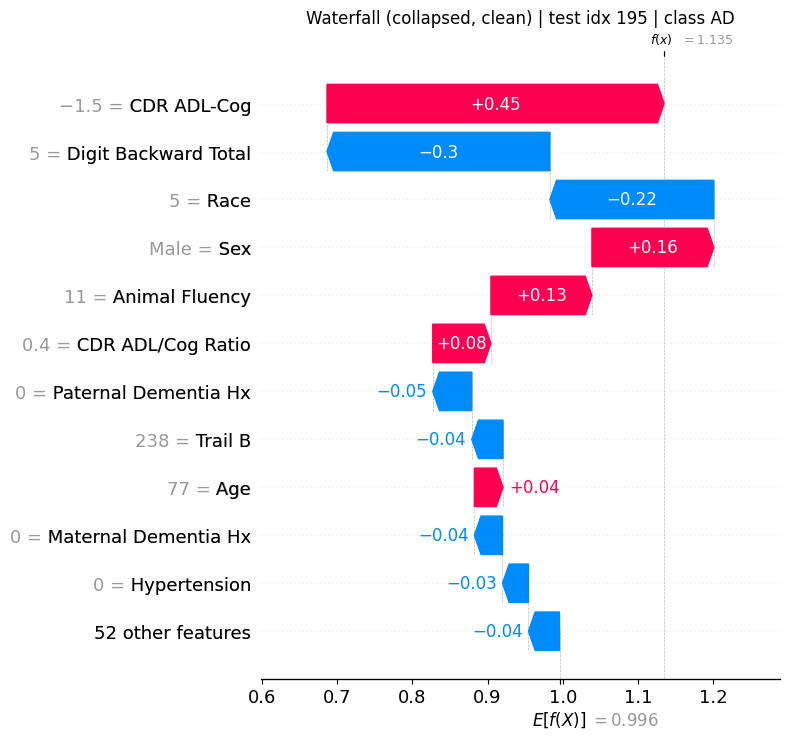

Saved: ..\output\shap_outputs\figures\waterfall_testidx_195_AD_clean.png

--- Collapsed waterfall for class: NoDementia_Hy ---


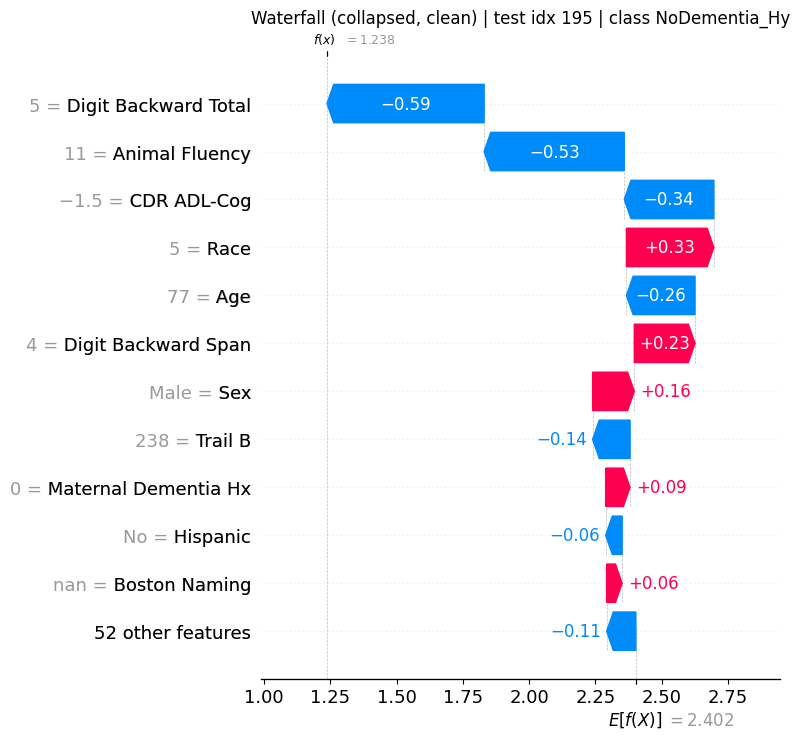

Saved: ..\output\shap_outputs\figures\waterfall_testidx_195_NoDementia_Hy_clean.png

--- Collapsed waterfall for class: PD_LBD ---


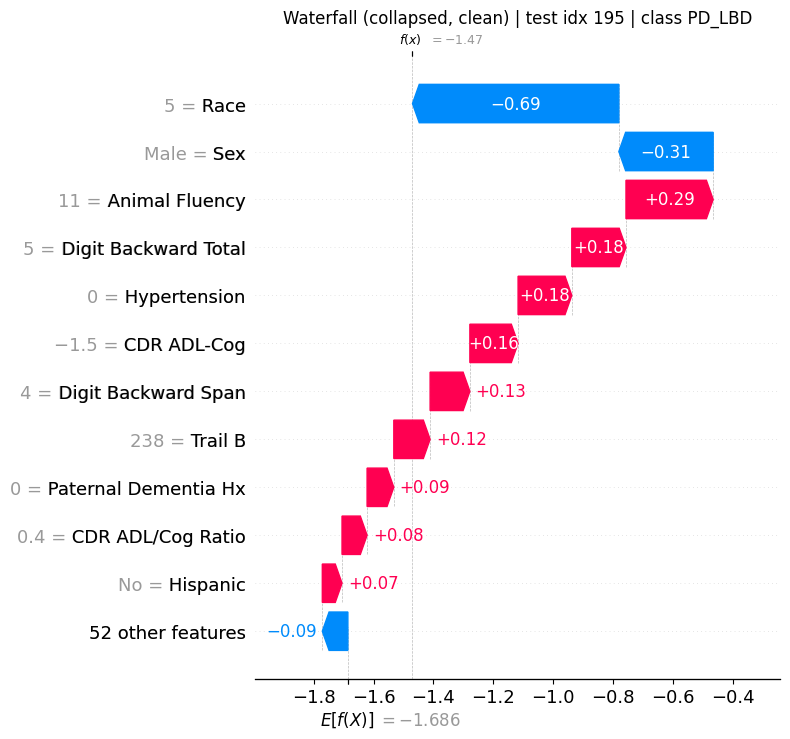

Saved: ..\output\shap_outputs\figures\waterfall_testidx_195_PD_LBD_clean.png

--- Collapsed waterfall for class: Vascular ---


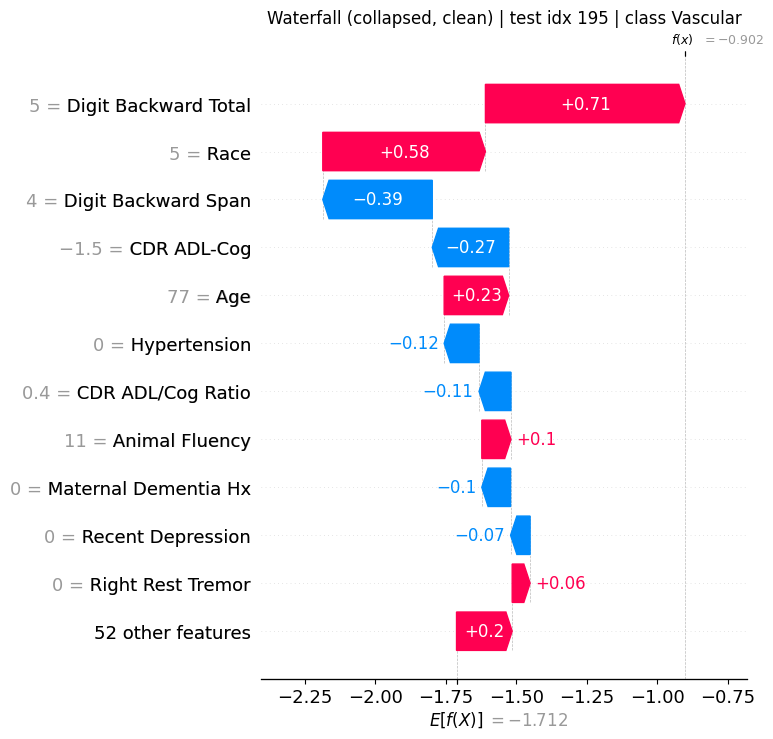

Saved: ..\output\shap_outputs\figures\waterfall_testidx_195_Vascular_clean.png
Explain subset row : 79
Original X_test idx: 31452
NACCID            : NACC817818
True label        : PD_LBD
Final prediction  : PD_LBD
Probabilities     : {np.str_('AD'): np.float64(0.0001), np.str_('NoDementia_Hy'): np.float64(0.0016), np.str_('PD_LBD'): np.float64(0.9983), np.str_('Vascular'): np.float64(0.0)}
Vascular margin   : -0.3900

--- Collapsed waterfall for class: AD ---


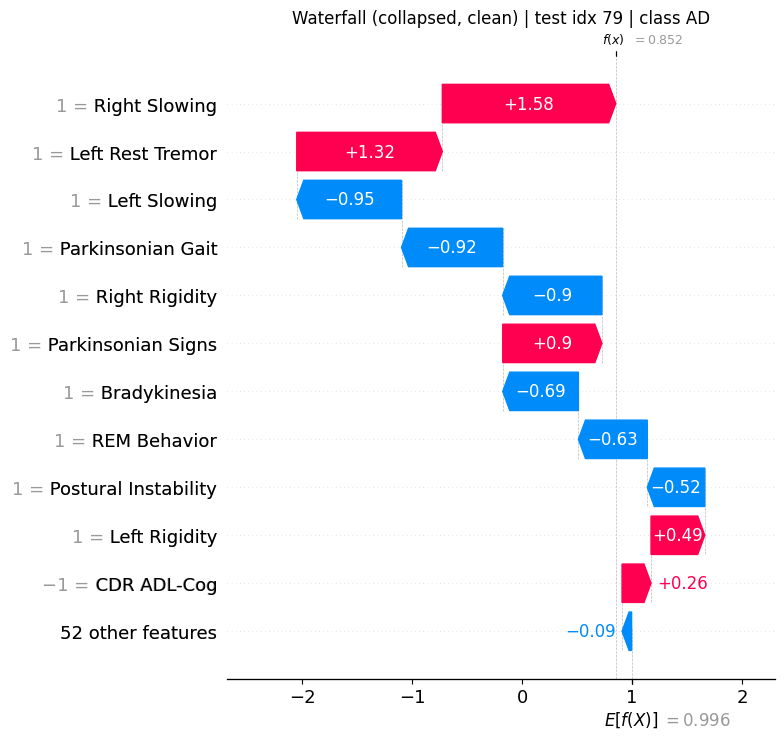

Saved: ..\output\shap_outputs\figures\waterfall_testidx_79_AD_clean.png

--- Collapsed waterfall for class: NoDementia_Hy ---


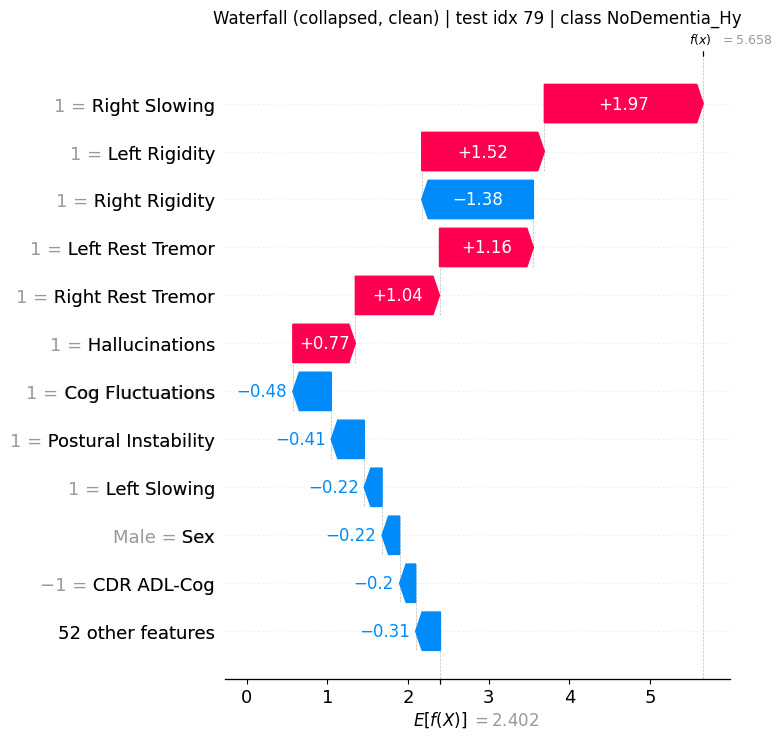

Saved: ..\output\shap_outputs\figures\waterfall_testidx_79_NoDementia_Hy_clean.png

--- Collapsed waterfall for class: PD_LBD ---


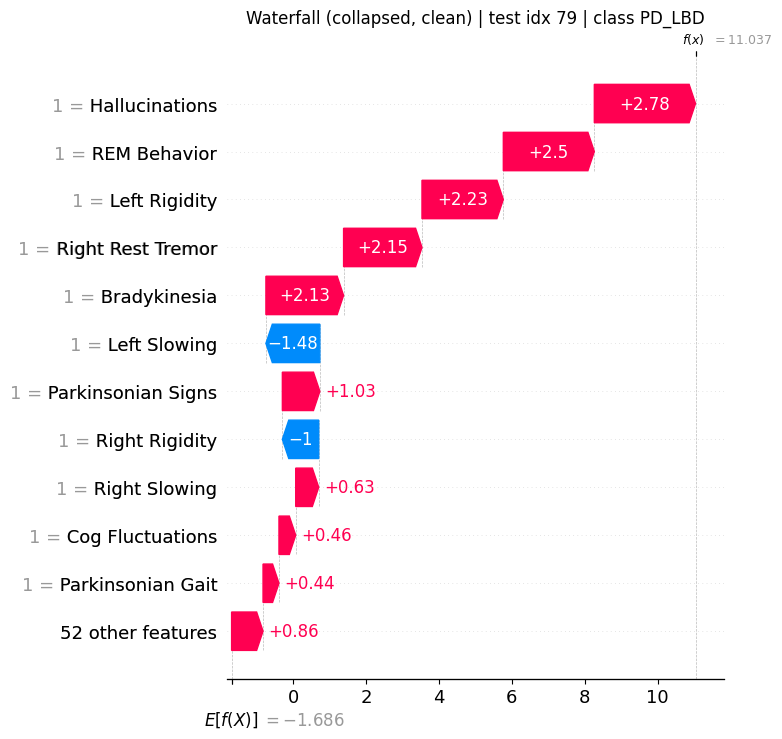

Saved: ..\output\shap_outputs\figures\waterfall_testidx_79_PD_LBD_clean.png

--- Collapsed waterfall for class: Vascular ---


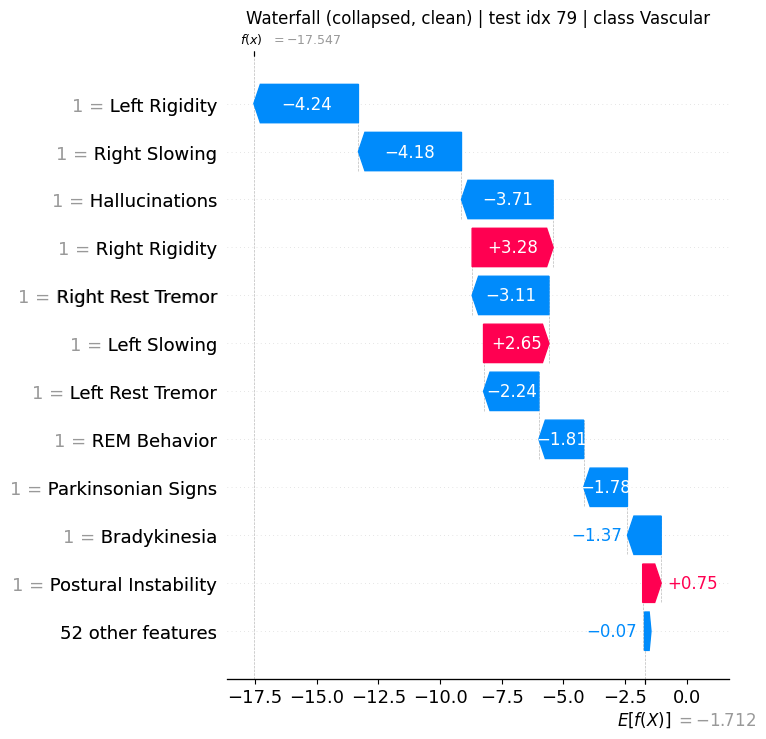

Saved: ..\output\shap_outputs\figures\waterfall_testidx_79_Vascular_clean.png
Explain subset row : 203
Original X_test idx: 3378
NACCID            : NACC087117
True label        : Vascular
Final prediction  : Vascular
Probabilities     : {np.str_('AD'): np.float64(0.0396), np.str_('NoDementia_Hy'): np.float64(0.0041), np.str_('PD_LBD'): np.float64(0.0), np.str_('Vascular'): np.float64(0.9563)}
Vascular margin   : 0.5663

--- Collapsed waterfall for class: AD ---


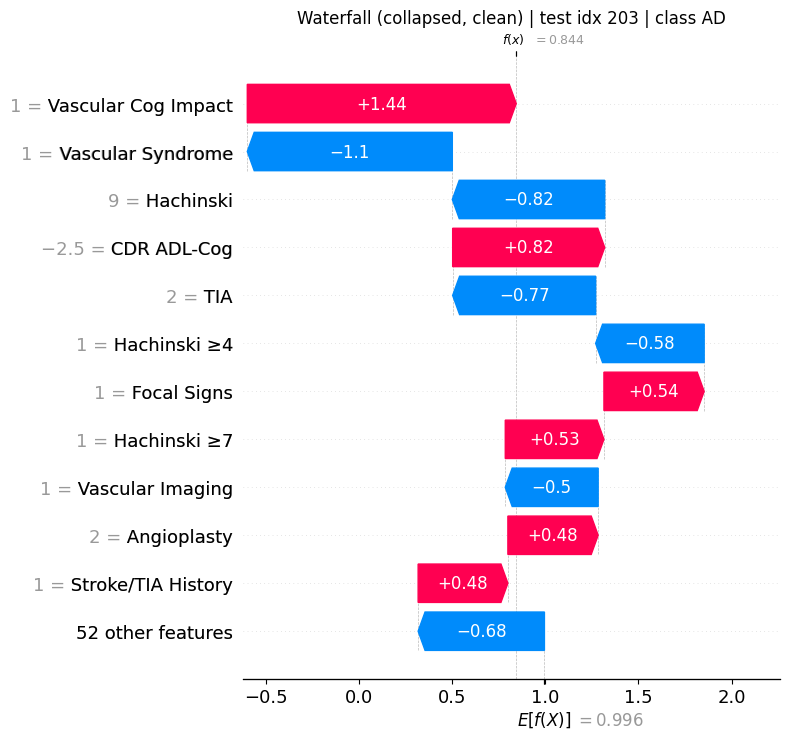

Saved: ..\output\shap_outputs\figures\waterfall_testidx_203_AD_clean.png

--- Collapsed waterfall for class: NoDementia_Hy ---


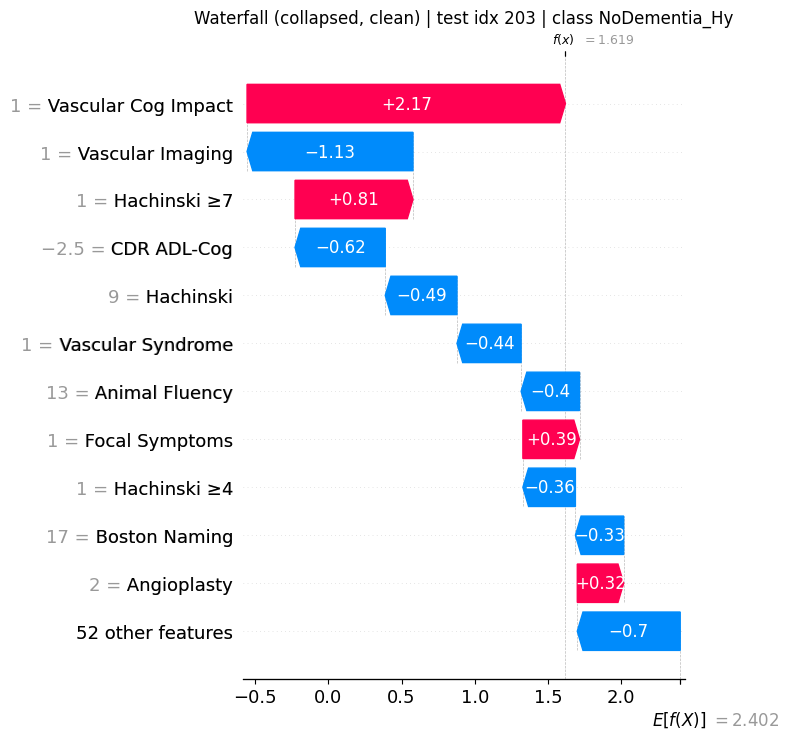

Saved: ..\output\shap_outputs\figures\waterfall_testidx_203_NoDementia_Hy_clean.png

--- Collapsed waterfall for class: PD_LBD ---


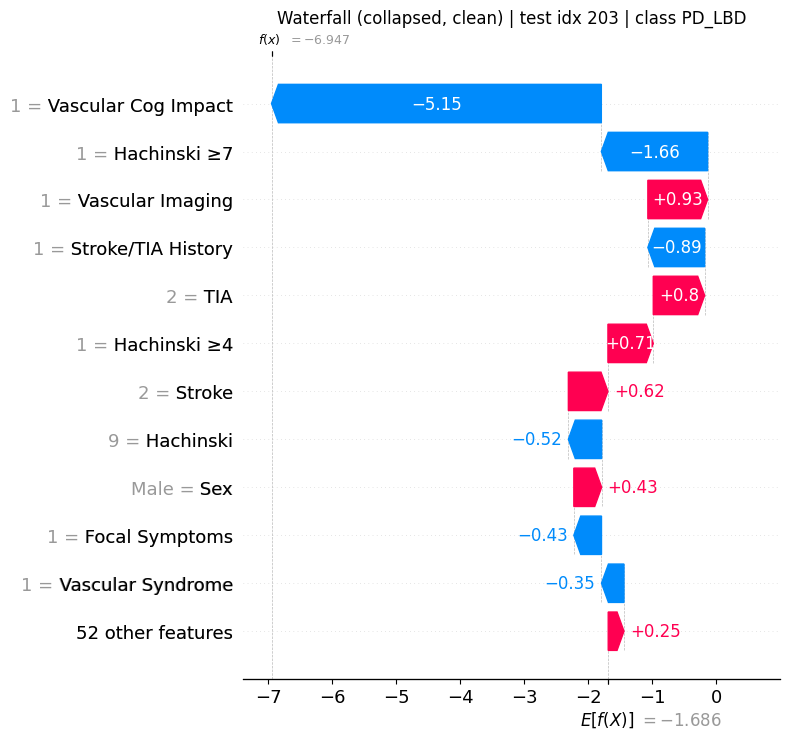

Saved: ..\output\shap_outputs\figures\waterfall_testidx_203_PD_LBD_clean.png

--- Collapsed waterfall for class: Vascular ---


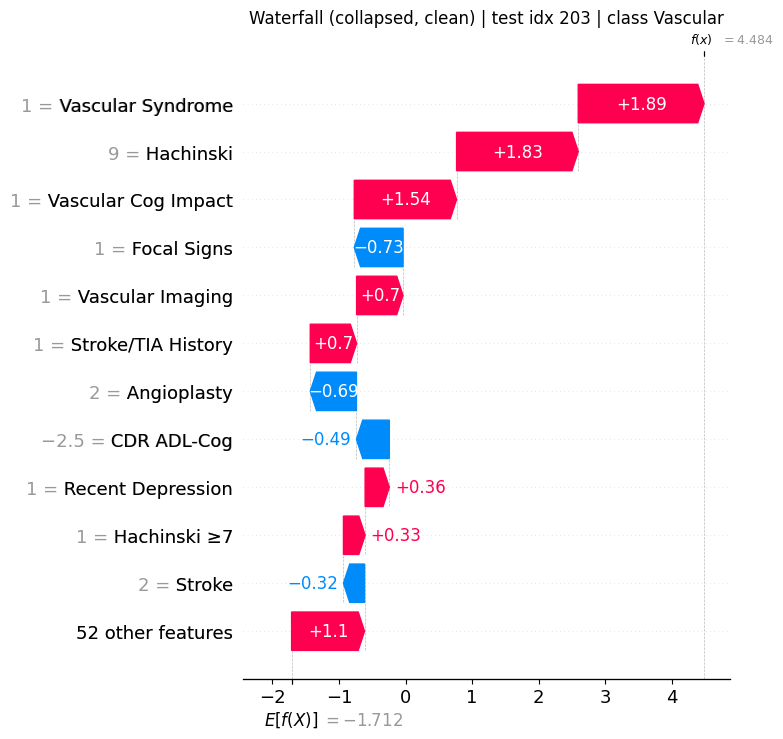

Saved: ..\output\shap_outputs\figures\waterfall_testidx_203_Vascular_clean.png
Explain subset row : 32
Original X_test idx: 26809
NACCID            : NACC696478
True label        : Vascular
Final prediction  : Vascular
Probabilities     : {np.str_('AD'): np.float64(0.3301), np.str_('NoDementia_Hy'): np.float64(0.0086), np.str_('PD_LBD'): np.float64(0.2564), np.str_('Vascular'): np.float64(0.4049)}
Vascular margin   : 0.0149

--- Collapsed waterfall for class: AD ---


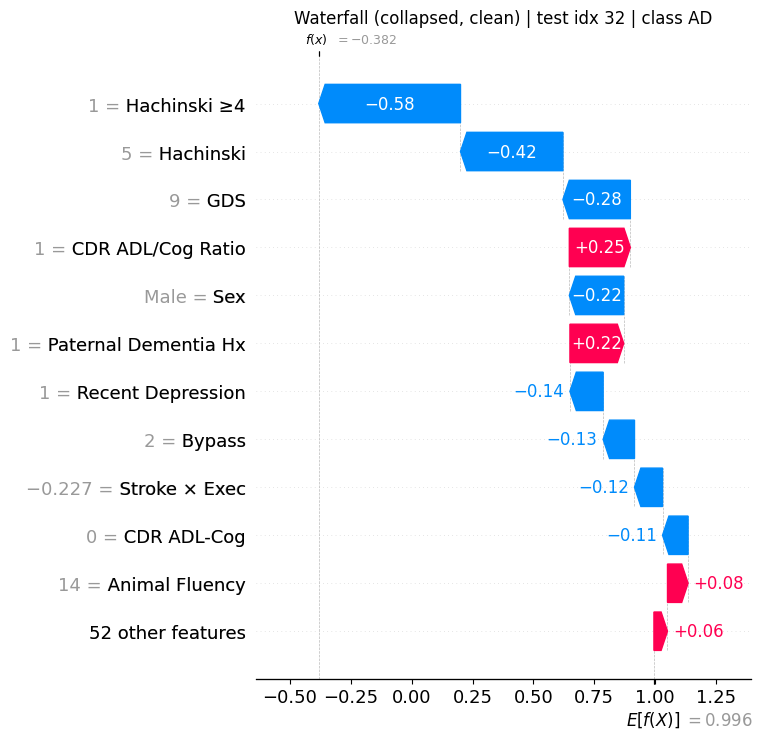

Saved: ..\output\shap_outputs\figures\waterfall_testidx_32_AD_clean.png

--- Collapsed waterfall for class: NoDementia_Hy ---


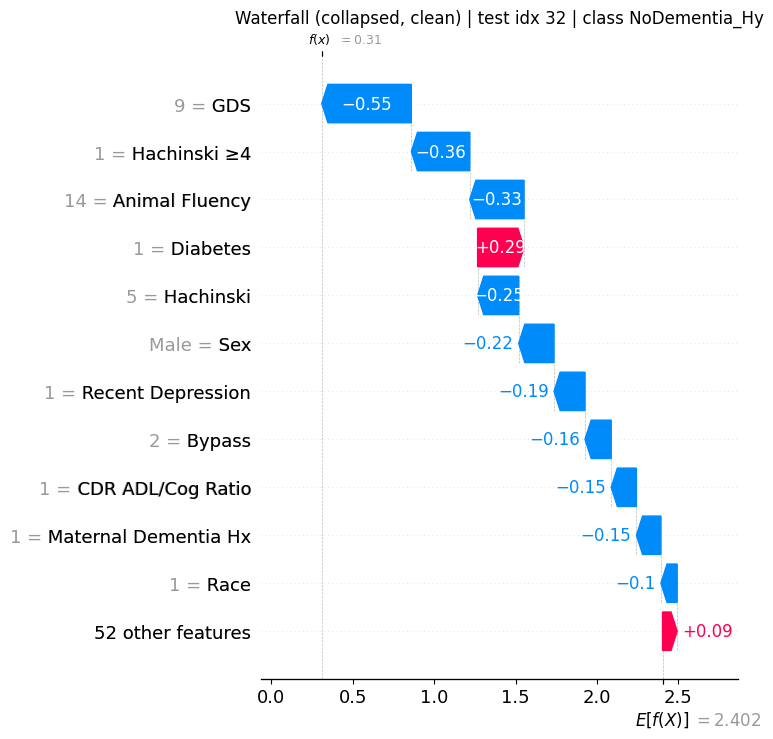

Saved: ..\output\shap_outputs\figures\waterfall_testidx_32_NoDementia_Hy_clean.png

--- Collapsed waterfall for class: PD_LBD ---


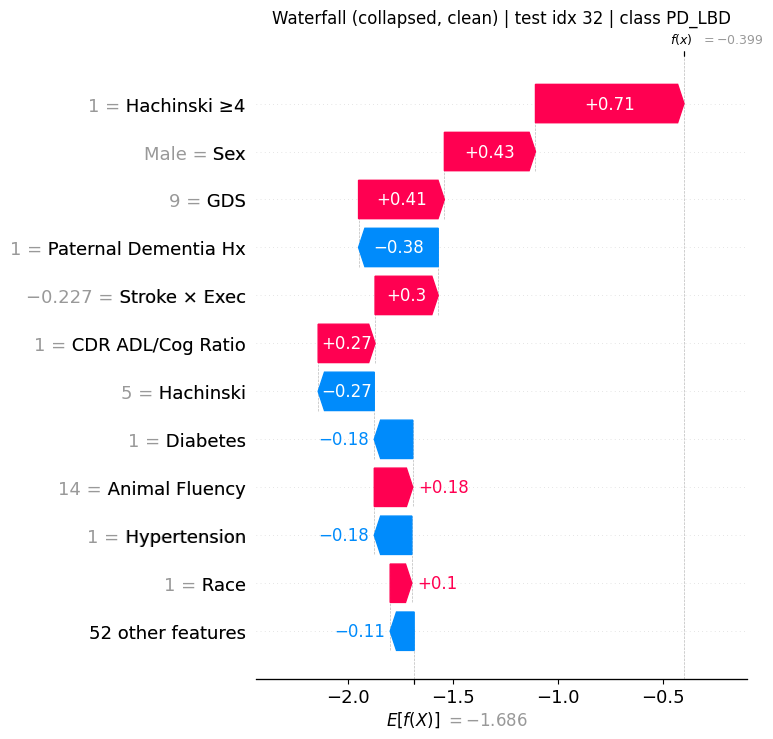

Saved: ..\output\shap_outputs\figures\waterfall_testidx_32_PD_LBD_clean.png

--- Collapsed waterfall for class: Vascular ---


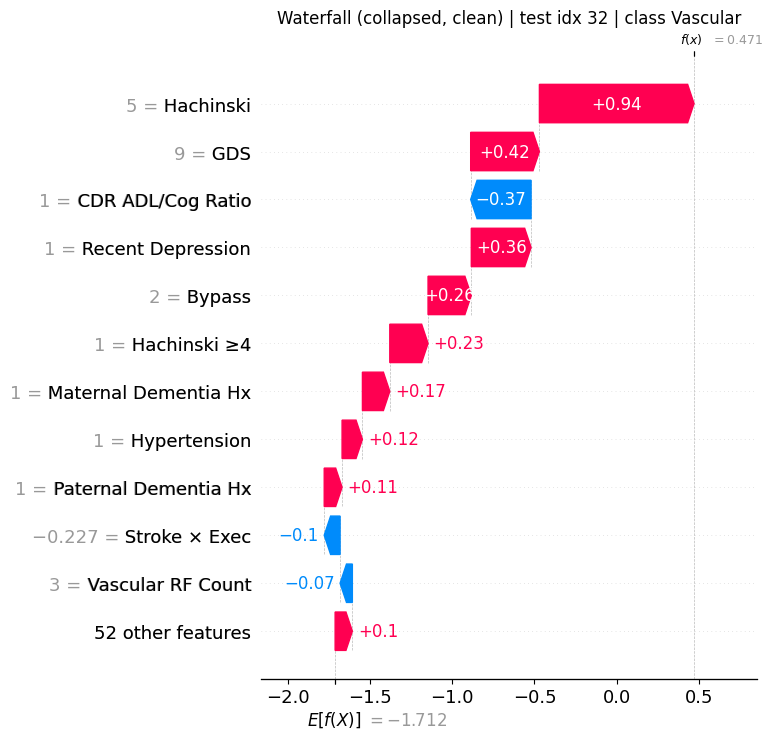

Saved: ..\output\shap_outputs\figures\waterfall_testidx_32_Vascular_clean.png


In [155]:

for i in example_indices:
    if i < 0 or i >= sample_size:
        print(f"Skipping i={i} because it is outside explained subset 0..{sample_size-1}")
        continue

    original_idx = X_test_explain.index[i]

    if "NACCID" in df4.columns:
        naccid = df4.loc[original_idx, "NACCID"]
    else:
        naccid = original_idx

    true_label = y_test_explain.iloc[i]

    proba_i = clf_best.predict_proba(X_test_explain.iloc[[i]])[0]
    final_pred_i = predict_with_vascular_threshold(
        proba_i.reshape(1, -1), class_order, best_T
    )[0]

    print("=" * 90)
    print(f"Explain subset row : {i}")
    print(f"Original X_test idx: {original_idx}")
    print(f"NACCID            : {naccid}")
    print(f"True label        : {true_label}")
    print(f"Final prediction  : {final_pred_i}")
    print(f"Probabilities     : {dict(zip(class_order, np.round(proba_i, 4)))}")
    print(f"Vascular margin   : {proba_i[vas_idx] - best_T:.4f}")

    raw_row = X_test_explain.iloc[i]

    for k, cls in enumerate(class_order):
        print(f"\n--- Collapsed waterfall for class: {cls} ---")

        if np.ndim(shap_exp.base_values) == 2:
            base_val = shap_exp.base_values[i, k]
        else:
            base_val = shap_exp.base_values[k]

        collapsed_exp, collapsed_df = build_collapsed_local_explanation(
            shap_vals_1d=shap_exp.values[i, :, k],
            feature_names=feature_names_pre,
            raw_row=raw_row,
            base_value=base_val,
            feature_label_func=plot_feature_name,
            hide_missing=True,
        )

        # Remove severity-style features from clinical display
        collapsed_df = collapsed_df[
            collapsed_df["feature_base"].apply(is_display_feature_clinical)
        ].copy()

        collapsed_df = collapsed_df.sort_values(
            "shap_value",
            key=lambda s: np.abs(s),
            ascending=False
        ).reset_index(drop=True)

        collapsed_exp = shap.Explanation(
            values=collapsed_df["shap_value"].to_numpy(),
            base_values=base_val,
            data=collapsed_df["raw_value"].to_numpy(),
            feature_names=collapsed_df["feature_label"].tolist()
        )

        plt.figure(figsize=(13, 7))
        shap.plots.waterfall(collapsed_exp, max_display=12, show=False)

        ax = plt.gca()
        ax.tick_params(axis='x', labelsize=9)
        for text in ax.texts:
            text.set_fontsize(8)

        plt.gcf().subplots_adjust(left=0.45)
        plt.title(
            f"Waterfall (collapsed, clean) | test idx {i} | class {cls}",
            fontsize=12
        )
        save_current_fig(f"waterfall_testidx_{i}_{cls}_clean.png")
        plt.close()

        # Optional probability-space local contribution table
        if prob_local_shap is not None and i in prob_local_example_map:
            pos = prob_local_example_map[i]

            if isinstance(prob_local_shap, list):
                prob_vals = np.asarray(prob_local_shap[k][pos])
                prob_base = float(np.mean(predict_proba_from_preprocessed(kernel_bg)[:, k]))
            else:
                arr = np.asarray(prob_local_shap)
                # expected shapes seen in SHAP versions: (n_samples, n_features, n_classes) or (n_classes, n_samples, n_features)
                if arr.ndim == 3 and arr.shape[0] == len(example_indices):
                    prob_vals = arr[pos, :, k]
                elif arr.ndim == 3 and arr.shape[0] == len(class_order):
                    prob_vals = arr[k, pos, :]
                else:
                    prob_vals = None
                prob_base = float(np.mean(predict_proba_from_preprocessed(kernel_bg)[:, k]))

            if prob_vals is not None:
                prob_collapsed = aggregate_shap_by_base(prob_vals, feature_names_pre)
                prob_collapsed = prob_collapsed[~prob_collapsed["feature_base"].apply(is_missing_feature_name)].copy()
                prob_collapsed["raw_value"] = prob_collapsed["feature_base"].map(
                    lambda c: format_category_value(c, raw_row[c]) if c in raw_row.index else np.nan
                )
                prob_collapsed["feature_label"] = prob_collapsed["feature_base"].map(
                    lambda c: plot_feature_name(c)
                )
                prob_collapsed = prob_collapsed.reindex(
                    prob_collapsed["shap_value"].abs().sort_values(ascending=False).index
                ).reset_index(drop=True)

                prob_out = prob_collapsed.head(12).copy()
                prob_out.insert(0, "NACCID", naccid)
                prob_out.insert(1, "test_index", i)
                prob_out.insert(2, "class", cls)
                prob_out.insert(3, "base_probability", prob_base)
                prob_out.insert(4, "predicted_probability", float(proba_i[k]))
                prob_out.to_csv(
                    TABLE_DIR / f"local_probability_shap_testidx_{i}_{cls}.csv",
                    index=False
                )


In [156]:

# Exporting top positive / negative local SHAP contributors per selected subject
# Collapsed to base-feature level so categorical dummy columns are grouped together.

local_signed_rows = []

for i in example_indices:
    if i >= sample_size:
        continue

    original_idx = X_test_explain.index[i]
    naccid = df4.loc[original_idx, "NACCID"] if "NACCID" in df4.columns else original_idx
    raw_row = X_test_explain.iloc[i]

    for k, cls in enumerate(class_order):
        collapsed_df = aggregate_shap_by_base(shap_exp.values[i, :, k], feature_names_pre)
        collapsed_df = collapsed_df[~collapsed_df["feature_base"].apply(is_missing_feature_name)].copy()
        collapsed_df["raw_value"] = collapsed_df["feature_base"].map(
            lambda c: format_category_value(c, raw_row[c]) if c in raw_row.index else "missing"
        )

        pos_df = collapsed_df.sort_values("shap_value", ascending=False).head(10)
        neg_df = collapsed_df.sort_values("shap_value", ascending=True).head(10)

        for rank, (_, row) in enumerate(pos_df.iterrows(), start=1):
            local_signed_rows.append({
                "NACCID": naccid,
                "test_index": i,
                "class": cls,
                "direction": "positive",
                "rank": rank,
                "feature_base": row["feature_base"],
                "feature_label": plot_feature_name(row["feature_base"]),
                "raw_value": row["raw_value"],
                "shap_value": row["shap_value"]
            })

        for rank, (_, row) in enumerate(neg_df.iterrows(), start=1):
            local_signed_rows.append({
                "NACCID": naccid,
                "test_index": i,
                "class": cls,
                "direction": "negative",
                "rank": rank,
                "feature_base": row["feature_base"],
                "feature_label": plot_feature_name(row["feature_base"]),
                "raw_value": row["raw_value"],
                "shap_value": row["shap_value"]
            })

local_signed_df = pd.DataFrame(local_signed_rows)
local_signed_df.to_csv(
    TABLE_DIR / "local_top_positive_negative_shap_collapsed.csv",
    index=False
)

display(local_signed_df.head(20))


,NACCID,test_index,class,direction,rank,feature_base,feature_label,raw_value,shap_value
0,NACC973323,195,AD,positive,1,NACCMOCA,MoCA,15.0,1.655893
1,NACC973323,195,AD,positive,2,CDRSUM,CDR Sum Boxes,3.5,0.476286
2,NACC973323,195,AD,positive,3,CDR_ADL_MINUS_COG,CDR ADL-Cog,-1.5,0.447730
3,NACC973323,195,AD,positive,4,CDRGLOB,CDR Global,0.5,0.246466
4,NACC973323,195,AD,positive,5,SEX,Sex,Male,0.161909
5,NACC973323,195,AD,positive,6,ANIMALS,Animal Fluency,11.0,0.134128
6,NACC973323,195,AD,positive,7,CDR_ADL_COG_RATIO,CDR ADL/Cog Ratio,0.4,0.077273
7,NACC973323,195,AD,positive,8,NACCAGE,Age,77.0,0.038060
8,NACC973323,195,AD,positive,9,DIGBACLS,Digit Backward Span,4.0,0.026506
9,NACC973323,195,AD,positive,10,DEP2YRS,Recent Depression,0.0,0.026002


## 11) Export top local SHAP drivers per subject

In [157]:

rows = []

for i in range(sample_size):
    original_idx = X_test_explain.index[i]
    naccid = df4.loc[original_idx, "NACCID"] if "NACCID" in df4.columns else original_idx
    raw_row = X_test_explain.iloc[i]

    for k, cls in enumerate(class_order):
        collapsed_df = aggregate_shap_by_base(shap_exp.values[i, :, k], feature_names_pre)
        collapsed_df = collapsed_df[~collapsed_df["feature_base"].apply(is_missing_feature_name)].copy()
        collapsed_df["abs_shap"] = collapsed_df["shap_value"].abs()
        collapsed_df["raw_value"] = collapsed_df["feature_base"].map(
            lambda c: format_category_value(c, raw_row[c]) if c in raw_row.index else "missing"
        )

        for rank, (_, row) in enumerate(collapsed_df.sort_values("abs_shap", ascending=False).head(10).iterrows(), start=1):
            rows.append({
                "NACCID": naccid,
                "test_index": i,
                "class": cls,
                "rank": rank,
                "feature_base": row["feature_base"],
                "feature_label": plot_feature_name(row["feature_base"]),
                "raw_value": row["raw_value"],
                "shap_value": row["shap_value"],
                "abs_shap": row["abs_shap"]
            })

local_top_shap_df = pd.DataFrame(rows)
local_csv = TABLE_DIR / "local_top10_shap_per_subject_collapsed.csv"
local_top_shap_df.to_csv(local_csv, index=False)

print("Saved:", local_csv)
display(local_top_shap_df.head(20))


Saved: ..\output\shap_outputs\tables\local_top10_shap_per_subject_collapsed.csv


,NACCID,test_index,class,rank,feature_base,feature_label,raw_value,shap_value,abs_shap
0,NACC056862,0,AD,1,NACCDAD,Paternal Dementia Hx,1.0,0.221036,0.221036
1,NACC056862,0,AD,2,CDRGLOB,CDR Global,0.0,-0.164311,0.164311
2,NACC056862,0,AD,3,SEX,Sex,Male,0.161909,0.161909
3,NACC056862,0,AD,4,CDRSUM,CDR Sum Boxes,0.0,-0.105564,0.105564
4,NACC056862,0,AD,5,CDR_ADL_MINUS_COG,CDR ADL-Cog,0.0,-0.105023,0.105023
5,NACC056862,0,AD,6,NACCMMSE,MMSE,29.0,-0.085947,0.085947
6,NACC056862,0,AD,7,HACHIN,Hachinski,0.0,0.075451,0.075451
7,NACC056862,0,AD,8,RACE,Race,1,0.065469,0.065469
8,NACC056862,0,AD,9,NACCMOM,Maternal Dementia Hx,1.0,0.060975,0.060975
9,NACC056862,0,AD,10,HYPERCHO,Hyperchol,0.0,0.050354,0.050354


## 12b) Recommended interpretation workflow

Use the collapsed plots/tables as the main outputs for reporting. They avoid duplicated one-hot categories, retain the original raw feature value in local explanations, and align better with the cohort feature definitions from `E8b_vascular_signal`. Keep the transformed-feature tables only as a technical appendix.

## 12) Finding interesting vascular cases near the decision boundary

In [158]:

interesting_vascular = threshold_df.assign(
    abs_margin=lambda d: np.abs(d["vascular_margin"])
).sort_values(["final_pred", "abs_margin"], ascending=[True, True])

display(
    interesting_vascular[
        ["NACCID", "true_label", "base_pred", "final_pred", "prob_vascular", "vascular_threshold", "vascular_margin"]
    ].head(20)
)


,NACCID,true_label,base_pred,final_pred,prob_vascular,vascular_threshold,vascular_margin
1362,NACC493067,AD,AD,AD,0.373254,0.39,-0.016746
1947,NACC700949,AD,AD,AD,0.369864,0.39,-0.020136
786,NACC333018,AD,AD,AD,0.363099,0.39,-0.026901
1245,NACC748379,Vascular,AD,AD,0.355229,0.39,-0.034771
1474,NACC722104,AD,AD,AD,0.351805,0.39,-0.038195
2548,NACC297075,AD,AD,AD,0.350144,0.39,-0.039856
2785,NACC343175,AD,AD,AD,0.334353,0.39,-0.055647
617,NACC644290,AD,AD,AD,0.330027,0.39,-0.059973
1576,NACC776644,AD,AD,AD,0.326237,0.39,-0.063763
2865,NACC956270,NoDementia_Hy,AD,AD,0.323713,0.39,-0.066287


In [159]:
# SHAP values here explain the multiclass logistic regression after preprocessing
# The final classifier also uses a vascular threshold override
# SHAP for the Vascular class
# vascular_margin = prob_vascular - threshold
# the collapsed feature tables are usually much easier to read than raw one-hot encoded features

In [160]:
print("INTERPRETATION GUIDE")
print("- Mean |SHAP| bar plots show which features matter most overall.")
print("- Beeswarm plots show both importance and direction.")
print("- Waterfall plots explain one participant at a time.")
print("- The 'clinical' plots hide broad severity variables to reveal subtype-specific signals.")
print("- Missingness indicators are kept in the model but hidden from display plots.")
print("- For vascular cases, also inspect vascular_margin and vascular_override_applied.")

INTERPRETATION GUIDE
- Mean |SHAP| bar plots show which features matter most overall.
- Beeswarm plots show both importance and direction.
- Waterfall plots explain one participant at a time.
- The 'clinical' plots hide broad severity variables to reveal subtype-specific signals.
- Missingness indicators are kept in the model but hidden from display plots.
- For vascular cases, also inspect vascular_margin and vascular_override_applied.
